# Vehicle Service Intelligence — Parked Energy & Wake Behavior

**Author:** Jason Waterman  
**Origin:** Extension of UC Berkeley AI/ML Professional Certificate Capstone Project  
**Created:** 2026-10-04  
**Last Updated:** 2026-10-04  
**Version:** 0.1.0  

---

## 📖 Description

This project extends the original **Vehicle State of Health (SoH) using AI/ML** capstone from battery health prediction toward **Vehicle Service Intelligence**.

The original project demonstrated that existing production-vehicle network data can be used to characterize 12V battery State of Health and identify vehicle signals correlated with battery and vehicle behavior.

This project asks the next question:

> **How can vehicle telemetry be transformed into trustworthy, context-aware, and actionable service intelligence?**

The initial use case is **Parked Energy & Wake Behavior**.

The objective is to characterize normal parked-energy behavior under different vehicle operating conditions, identify behavior that is inconsistent with its operating context, gather corroborating evidence, and determine when an observed anomaly should result in monitoring, additional data collection, or a service action.

A key design objective is **false-positive suppression**. An anomaly does not automatically generate a customer or service notification.

In [31]:
# ============================================================
# Vehicle Service Intelligence — Parked Energy & Wake Behavior
# Project setup
# ============================================================

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Project paths
DATA_PATH = Path("outputs/logs/cycle_metrics_all_operating-modes.csv")

print("Project setup complete.")

Project setup complete.


## 1. Project Objectives

The project investigates an end-to-end Vehicle Service Intelligence workflow:

**Vehicle Signals → Signal Observability → Operating Context → Expected Behavior → Anomaly Detection → Confidence → Service Decision → Learning**

### 🔑 Primary Objectives

1. **Characterize normal parked-energy behavior**
   - Quiescent parked state
   - Known intentional high-load conditions
   - HV charging

2. **Account for signal observability**
   - Distinguish fresh vehicle measurements from stale or forward-filled values
   - Avoid interpreting unavailable vehicle data as continuously measured physical behavior

3. **Establish context-aware normal behavior**
   - Determine how energy behavior changes with vehicle operating state
   - Avoid defining normal behavior using a single fixed threshold

4. **Detect deviations from expected behavior**
   - Explore statistical and ML-based anomaly-detection approaches
   - Use only physically meaningful and observable features

5. **Suppress false positives**
   - Separate anomaly detection from notification
   - Consider persistence, recurrence, signal quality, operating context, and corroborating evidence

6. **Translate vehicle intelligence into service intelligence**
   - Monitor silently when evidence is weak
   - Gather additional evidence when confidence is insufficient
   - Escalate only high-confidence, actionable conditions

### 💡 Core Principle

> **The objective is not to detect every anomaly. The objective is to identify the smallest set of high-confidence, actionable conditions that deserve human attention.**

## 2. Dataset & Operating Context

The analysis uses charge/discharge cycle features derived from production-vehicle network data collected during the original Vehicle State of Health project.

The feature-generation pipeline is contained in:

`cs_gen_charge-cycle-metrics.ipynb`

The consolidated dataset used for this analysis is:

`outputs/logs/cycle_metrics_all_operating-modes.csv`

The current dataset contains **75 detected LV recharge cycles across 24 vehicle log files**.

### Operating-State Metadata

Each cycle is assigned an `operating_mode` and `mode_confidence` based on the known test context contained in the source log information.

The current operating modes are:

- **QUIESCENT** — vehicle parked without a known intentional high load
- **INTENTIONAL_LOAD** — vehicle parked with a known intentionally applied high electrical load
- **HV_CHARGING** — vehicle parked while the HV battery is being charged

The specific electrical loads used during the intentional-load tests were not independently documented. Therefore, intentional-load cycles are treated as one broad operating class rather than attempting to infer specific loads from the resulting electrical behavior.

### Classification Confidence

- **CONFIRMED** — operating condition is explicitly supported by the source log/test description
- **INFERRED** — operating condition is believed to be quiescent based on available test context but was not independently verified

### 💡 Important Assumption

All three operating modes represent **known or assumed normal vehicle behavior**.

The dataset does **not** contain a confirmed vehicle failure event.

Therefore, this project is framed as **normal-behavior characterization and anomaly detection**, not supervised failure classification.

In [32]:
# ============================================================
# Load cycle-level feature dataset
# ============================================================

df = pd.read_csv(DATA_PATH)

# Update legacy metadata column names
df = df.rename(columns={
    "operating_regime": "operating_mode",
    "regime_confidence": "mode_confidence"
})

print(f"Dataset loaded: {DATA_PATH}")
print(f"Rows:    {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

display(df.head())

Dataset loaded: outputs/logs/cycle_metrics_all_operating-modes.csv
Rows:    75
Columns: 129


,cycle_start,cycle_end,source_file,cycle_id,cycle_idx,duration_s,V_peak_charge,V_mean_charge,V_tail_mean,time_absorption_s,I_bulk_mean,I_min,soc_start_pct,soc_end_pct,soc_gain_pct,t80_s,Ah_in,Ah_out_prev,discharge_duration_s,discharge_Ah_per_hr,discharge_V_start,discharge_V_end,discharge_V_drop,discharge_V_decay_per_hr,discharge_I_mean,discharge_I_p90,R_dyn_ohm,target_soh1,IBS_BatteryVoltage__mean,IBS_BatteryVoltage__median,IBS_BatteryVoltage__std,IBS_BatteryVoltage__min,IBS_BatteryVoltage__max,IBS_BatteryVoltage__p10,IBS_BatteryVoltage__p90,IBS_BatteryVoltage__first,IBS_BatteryVoltage__last,IBS_BatteryCurrent__mean,IBS_BatteryCurrent__median,IBS_BatteryCurrent__std,IBS_BatteryCurrent__min,IBS_BatteryCurrent__max,IBS_BatteryCurrent__p10,IBS_BatteryCurrent__p90,IBS_BatteryCurrent__first,IBS_BatteryCurrent__last,IBS_BatteryTemperature__mean,IBS_BatteryTemperature__median,IBS_BatteryTemperature__std,IBS_BatteryTemperature__min,...,IBS_AvgRi__p90,IBS_AvgRi__first,IBS_AvgRi__last,IBS_AvailableCapacity__mean,IBS_AvailableCapacity__median,IBS_AvailableCapacity__std,IBS_AvailableCapacity__min,IBS_AvailableCapacity__max,IBS_AvailableCapacity__p10,IBS_AvailableCapacity__p90,IBS_AvailableCapacity__first,IBS_AvailableCapacity__last,IBS_DischargeableAh__mean,IBS_DischargeableAh__median,IBS_DischargeableAh__std,IBS_DischargeableAh__min,IBS_DischargeableAh__max,IBS_DischargeableAh__p10,IBS_DischargeableAh__p90,IBS_DischargeableAh__first,IBS_DischargeableAh__last,IBS_NominalCapacity__mean,IBS_NominalCapacity__median,IBS_NominalCapacity__std,IBS_NominalCapacity__min,IBS_NominalCapacity__max,IBS_NominalCapacity__p10,IBS_NominalCapacity__p90,IBS_NominalCapacity__first,IBS_NominalCapacity__last,IBS_Sulfation__mean,IBS_Sulfation__median,IBS_Sulfation__std,IBS_Sulfation__min,IBS_Sulfation__max,IBS_Sulfation__p10,IBS_Sulfation__p90,IBS_Sulfation__first,IBS_Sulfation__last,IBS_BatteryDefect__mean,IBS_BatteryDefect__median,IBS_BatteryDefect__std,IBS_BatteryDefect__min,IBS_BatteryDefect__max,IBS_BatteryDefect__p10,IBS_BatteryDefect__p90,IBS_BatteryDefect__first,IBS_BatteryDefect__last,operating_mode,mode_confidence
0,2025-06-26 02:20:47+00:00,2025-06-26 02:40:03+00:00,12V Management 2025-06-25_22-20-47_IBS_only_c...,12V Management 2025-06-25_22-20-47_IBS_only_c...,0,"1,156.000",14.115,14.107,14.101,0.000,2.973,-15.183,"7,650.000","7,850.000",200.000,0.000,0.967,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.059,0.934,14.106,14.109,0.054,12.953,14.117,14.103,14.113,14.100,12.953,2.973,2.712,1.284,-15.183,5.261,2.091,4.487,5.246,-15.183,23.500,23.500,0.000,23.500,...,6.070,6.070,6.070,33.000,33.000,0.000,33.000,33.000,33.000,33.000,33.000,33.000,32.915,33.000,0.272,32.400,33.300,32.500,33.300,32.400,33.300,50.000,50.000,0.000,50.000,50.000,50.000,50.000,50.000,50.000,1.000,1.000,0.000,1.000,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,QUIESCENT,INFERRED
1,2025-06-26 11:24:45+00:00,2025-06-26 12:02:32+00:00,12V Management 2025-06-25_22-20-47_IBS_only_c...,12V Management 2025-06-25_22-20-47_IBS_only_c...,1,"2,267.000",14.114,14.102,14.100,0.000,4.277,-14.893,"7,150.000","7,700.000",550.000,0.000,2.705,80.287,"31,480.000",9.181,12.898,12.338,0.560,0.064,12.620,13.319,-0.062,0.934,14.102,14.106,0.041,12.914,14.115,14.091,14.111,14.050,12.914,4.277,3.530,2.334,-14.893,14.278,2.210,7.630,14.278,-14.893,21.000,21.000,0.000,21.000,...,6.070,6.070,6.070,33.000,33.000,0.000,33.000,33.000,33.000,33.000,33.000,33.000,31.484,31.600,0.728,29.900,32.500,30.300,32.300,29.900,32.500,50.000,50.000,0.000,50.000,50.000,50.000,50.000,50.000,50.000,1.000,1.000,0.000,1.000,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,QUIESCENT,INFERRED
2,2025-06-26 13:09:11+00:00,2025-06-26 13:19:50+00:00,12V Management 2025-06-25_22-20-47_IBS_only_c...,12V Management 2025-06-25_22-20-47_IBS_only_c...,2,639.000,14.114,14.104,14.101,0.000,2.915,-14.835,"7,550.000","7,650.000",100.000,0.000,0.528,7.185,"3,997.000",6.471,12.857

In [33]:
# ============================================================
# Verify operating-state metadata
# ============================================================

mode_summary = (
    df.groupby(
        ["operating_mode", "mode_confidence"]
    )
    .size()
    .reset_index(name="cycle_count")
)

display(mode_summary)

,operating_mode,mode_confidence,cycle_count
0,HV_CHARGING,CONFIRMED,1
1,INTENTIONAL_LOAD,CONFIRMED,26
2,QUIESCENT,CONFIRMED,14
3,QUIESCENT,INFERRED,34


In [34]:
# ============================================================
# Source-file / operating-state audit
# ============================================================

source_summary = (
    df.groupby(
        [
            "source_file",
            "operating_mode",
            "mode_confidence"
        ]
    )
    .size()
    .reset_index(name="cycle_count")
    .sort_values(
        [
            "operating_mode",
            "mode_confidence",
            "source_file"
        ]
    )
)

display(source_summary)

,source_file,operating_mode,mode_confidence,cycle_count
11,12V_IBS_Charge_during_L2_HV_charning_after_IBS...,HV_CHARGING,CONFIRMED,1
0,12V IBS Full load 2025-08-20_22-17-18_L001_IBS...,INTENTIONAL_LOAD,CONFIRMED,5
1,12V IBS Full load 2025-08-20_22-17-18_L002_IBS...,INTENTIONAL_LOAD,CONFIRMED,4
2,12V IBS Full load 2025-08-20_22-17-18_L003_IBS...,INTENTIONAL_LOAD,CONFIRMED,4
3,12V IBS Full load 2025-08-20_22-17-18_L004_IBS...,INTENTIONAL_LOAD,CONFIRMED,4
4,12V IBS Full load 2025-08-20_22-17-18_L005_IBS...,INTENTIONAL_LOAD,CONFIRMED,5
5,12V IBS Full load 2025-08-20_22-17-18_L006_IBS...,INTENTIONAL_LOAD,CONFIRMED,4
12,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...,QUIESCENT,CONFIRMED,4
13,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...,QUIESCENT,CONFIRMED,5
14,12V_LIN_Normal_Dischare_12Hrs_Vehicle_sleep-Ch...,QUIESCENT,CONFIRMED,5


In [35]:
# ============================================================
# Feature completeness
# ============================================================

analysis_features = [
    # Discharge / parked interval
    "Ah_out_prev",
    "discharge_duration_s",
    "discharge_Ah_per_hr",
    "discharge_V_start",
    "discharge_V_end",
    "discharge_V_drop",
    "discharge_V_decay_per_hr",
    "discharge_I_mean",
    "discharge_I_p90",

    # Recharge interval
    "duration_s",
    "Ah_in",
    "I_bulk_mean",
    "V_peak_charge",
    "V_mean_charge",
    "V_tail_mean",
]

feature_completeness = pd.DataFrame({
    "feature": analysis_features,
    "available": [
        df[col].notna().sum()
        for col in analysis_features
    ],
    "missing": [
        df[col].isna().sum()
        for col in analysis_features
    ],
})

feature_completeness["available_pct"] = (
    feature_completeness["available"] /
    len(df) * 100
)

display(feature_completeness)

,feature,available,missing,available_pct
0,Ah_out_prev,51,24,68.000
1,discharge_duration_s,51,24,68.000
2,discharge_Ah_per_hr,51,24,68.000
3,discharge_V_start,51,24,68.000
4,discharge_V_end,51,24,68.000
5,discharge_V_drop,51,24,68.000
6,discharge_V_decay_per_hr,51,24,68.000
7,discharge_I_mean,51,24,68.000
8,discharge_I_p90,51,24,68.000
9,duration_s,75,0,100.000


In [36]:
# ============================================================
# Define analysis populations
# ============================================================

# All detected recharge cycles
df_all = df.copy()

# Cycles with a complete preceding discharge interval
df_discharge = df[
    df["discharge_duration_s"].notna()
].copy()

# Confirmed operating-state observations only
df_confirmed = df[
    df["mode_confidence"] == "CONFIRMED"
].copy()

# Confirmed observations with complete discharge interval
df_discharge_confirmed = df[
    (df["mode_confidence"] == "CONFIRMED") &
    (df["discharge_duration_s"].notna())
].copy()

print("Analysis populations")
print("--------------------")
print(f"All recharge cycles:                   {len(df_all)}")
print(f"Cycles with preceding discharge data:  {len(df_discharge)}")
print(f"Confirmed operating-state cycles:      {len(df_confirmed)}")
print(f"Confirmed + discharge data:            {len(df_discharge_confirmed)}")

Analysis populations
--------------------
All recharge cycles:                   75
Cycles with preceding discharge data:  51
Confirmed operating-state cycles:      41
Confirmed + discharge data:            31


### 💡 Initial Dataset Observations

The dataset contains two related analytical populations:

1. **Recharge-event dataset** — all detected recharge cycles for which recharge behavior can be analyzed.
2. **Full energy-cycle dataset** — cycles for which a complete preceding parked/discharge interval is also available.

Missing preceding-discharge features are not automatically treated as missing-data errors. In many cases, the first detected recharge event in a source log does not contain the complete preceding interval required to calculate those features.

Operating-state confidence is retained throughout the analysis so that inferred quiescent conditions can be distinguished from explicitly documented operating conditions.

No observations are removed at this stage.

## 3. Signal Observability & Data Validity

Before modeling vehicle behavior, it is necessary to determine whether the underlying telemetry represents a fresh physical measurement.

The vehicle-network logs used by this project were downsampled to a regular time interval. When an ECU or network stops transmitting during vehicle sleep, the preprocessing pipeline may carry the **last known signal value forward**.

Therefore:

> **A numerical value in the downsampled dataset does not necessarily represent a new physical observation.**

For example, the IBS may report a battery current immediately before the vehicle network enters sleep. If the IBS stops transmitting, that last current value may remain present in the downsampled dataset for an extended period.

Naively integrating this forward-filled value could incorrectly imply continuous battery discharge.

### Signal Interpretation Principle

Vehicle telemetry should therefore be interpreted as:

**Signal Value + Timestamp/Freshness + Vehicle Operating State**

rather than signal value alone.

### Implications for this Analysis

Recharge-cycle measurements are generally observable because the relevant vehicle networks are active during recharge.

Long-duration parked-current measurements require greater care because the IBS or related ECUs may stop transmitting during deep vehicle sleep.

The analysis will therefore distinguish between:

- **Observed physical behavior**
- **Forward-filled / potentially stale signal values**
- **Derived features that remain trustworthy**
- **Features whose interpretation depends on signal observability**

### 💡 Observation

This is not simply a data-cleaning problem.

Signal observability is itself part of **Vehicle Intelligence** and must be considered before telemetry can be used to make a service decision.

In [37]:
# ============================================================
# Signal observability sanity check
# Compare apparent discharge Ah with subsequent recharge Ah
# ============================================================

df_balance = df_discharge.copy()

# Ratio of subsequent charge returned to apparent preceding
# battery discharge.
df_balance["charge_balance_ratio"] = (
    df_balance["Ah_in"] /
    df_balance["Ah_out_prev"]
)

balance_summary = (
    df_balance
    .groupby(
        ["operating_mode", "mode_confidence"]
    )
    .agg(
        cycles=("cycle_id", "count"),
        median_Ah_out=("Ah_out_prev", "median"),
        median_Ah_in=("Ah_in", "median"),
        median_balance_ratio=("charge_balance_ratio", "median"),
    )
    .reset_index()
)

display(balance_summary)

,operating_mode,mode_confidence,cycles,median_Ah_out,median_Ah_in,median_balance_ratio
0,INTENTIONAL_LOAD,CONFIRMED,20,8.226,8.509,1.018
1,QUIESCENT,CONFIRMED,11,29.256,1.172,0.041
2,QUIESCENT,INFERRED,20,7.174,7.283,1.019


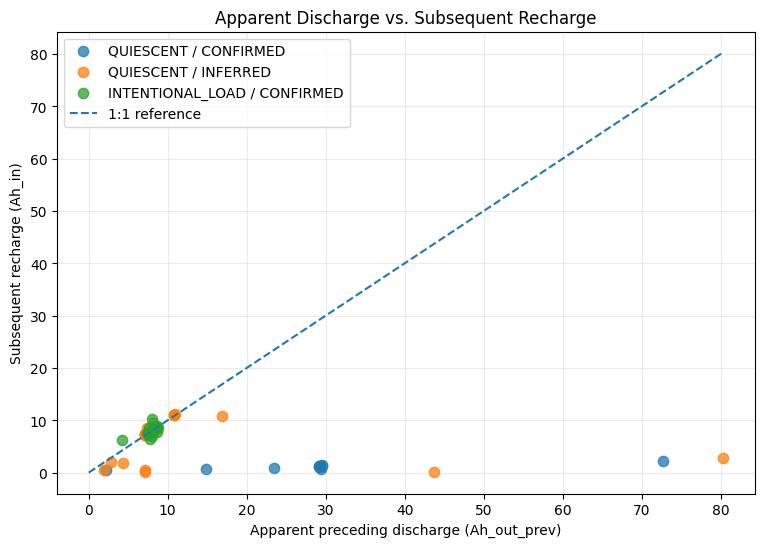

In [38]:
# ============================================================
# Apparent discharge Ah vs subsequent recharge Ah
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

plot_groups = [
    ("QUIESCENT", "CONFIRMED"),
    ("QUIESCENT", "INFERRED"),
    ("INTENTIONAL_LOAD", "CONFIRMED"),
]

for mode, confidence in plot_groups:

    subset = df_balance[
        (df_balance["operating_mode"] == mode) &
        (df_balance["mode_confidence"] == confidence)
    ]

    ax.scatter(
        subset["Ah_out_prev"],
        subset["Ah_in"],
        label=f"{mode} / {confidence}",
        alpha=0.75,
        s=55
    )

# Idealized 1:1 charge-balance reference
max_val = max(
    df_balance["Ah_out_prev"].max(),
    df_balance["Ah_in"].max()
)

ax.plot(
    [0, max_val],
    [0, max_val],
    linestyle="--",
    linewidth=1.5,
    label="1:1 reference"
)

ax.set_xlabel("Apparent preceding discharge (Ah_out_prev)")
ax.set_ylabel("Subsequent recharge (Ah_in)")
ax.set_title(
    "Apparent Discharge vs. Subsequent Recharge"
)

ax.grid(alpha=0.25)
ax.legend()

plt.show()

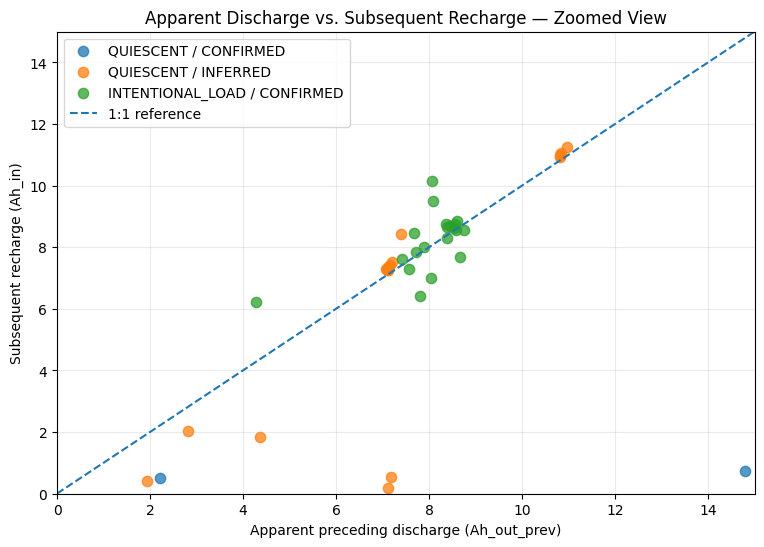

In [39]:
# ============================================================
# Zoomed view: apparent discharge vs subsequent recharge
# Focus on 0–15 Ah region
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

plot_groups = [
    ("QUIESCENT", "CONFIRMED"),
    ("QUIESCENT", "INFERRED"),
    ("INTENTIONAL_LOAD", "CONFIRMED"),
]

for mode, confidence in plot_groups:

    subset = df_balance[
        (df_balance["operating_mode"] == mode) &
        (df_balance["mode_confidence"] == confidence)
    ]

    ax.scatter(
        subset["Ah_out_prev"],
        subset["Ah_in"],
        label=f"{mode} / {confidence}",
        alpha=0.75,
        s=55
    )

# 1:1 reference line
ax.plot(
    [0, 15],
    [0, 15],
    linestyle="--",
    linewidth=1.5,
    label="1:1 reference"
)

# Zoom into the region of interest
ax.set_xlim(0, 15)
ax.set_ylim(0, 15)

ax.set_xlabel("Apparent preceding discharge (Ah_out_prev)")
ax.set_ylabel("Subsequent recharge (Ah_in)")
ax.set_title(
    "Apparent Discharge vs. Subsequent Recharge — Zoomed View"
)

ax.grid(alpha=0.25)
ax.legend()

plt.show()

### 💡 Charge-Balance Observation

The full-range and zoomed charge-balance plots demonstrate two distinct behaviors.

Confirmed intentional-load cycles generally cluster near the 1:1 reference between apparent preceding discharge (`Ah_out_prev`) and subsequent recharge (`Ah_in`). This supports the validity of the discharge integration when IBS current remains observable.

Quiescent cycles show mixed behavior. Some cycles also exhibit plausible charge balance, while others report large apparent discharge with little subsequent recharge.

This behavior is consistent with the known preprocessing method: when the vehicle network enters sleep and the IBS stops transmitting, the downsampled dataset carries the last known current value forward. Integrating these stale values can therefore produce physically unrealistic apparent discharge.

Importantly, **operating mode alone does not determine signal validity**. A quiescent interval may contain either observable or stale IBS data.

This suggests that Vehicle Service Intelligence should treat **signal observability as a separate state variable from vehicle operating state** and should apply physical-consistency checks before derived telemetry features are trusted.

In [40]:
# ============================================================
# Charge-balance behavior by source log
# ============================================================

source_balance = (
    df_balance
    .groupby(
        [
            "source_file",
            "operating_mode",
            "mode_confidence"
        ]
    )
    .agg(
        cycles=("cycle_id", "count"),
        median_Ah_out=("Ah_out_prev", "median"),
        median_Ah_in=("Ah_in", "median"),
        median_balance_ratio=("charge_balance_ratio", "median"),
    )
    .reset_index()
    .sort_values("median_balance_ratio")
)

display(source_balance)

,source_file,operating_mode,mode_confidence,cycles,median_Ah_out,median_Ah_in,median_balance_ratio
13,12V_Management_2025-06-26_13-39-25_IBS_only.csv,QUIESCENT,INFERRED,1,43.725,0.056,0.001
11,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...,QUIESCENT,CONFIRMED,4,29.286,1.161,0.040
10,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...,QUIESCENT,CONFIRMED,3,29.307,1.329,0.045
12,12V_LIN_Normal_Dischare_12Hrs_Vehicle_sleep-Ch...,QUIESCENT,CONFIRMED,4,19.123,0.850,0.045
6,12V Management 2025-06-25_22-20-47_IBS_only_c...,QUIESCENT,INFERRED,2,43.736,1.617,0.054
14,IBS 2025-10-04_13-33-54_L006_IBS_only_cleaned.csv,QUIESCENT,INFERRED,1,1.938,0.403,0.208
16,IBS 2025-10-04_13-33-54_L010_IBS_only_cleaned.csv,QUIESCENT,INFERRED,1,4.362,1.822,0.418
15,IBS 2025-10-04_13-33-54_L008_IBS_only_cleaned.csv,QUIESCENT,INFERRED,1,2.816,2.043,0.725
4,12V IBS Full load 2025-08-20_22-17-18_L005_IBS...,INTENTIONAL_LOAD,CONFIRMED,4,7.934,7.642,0.955
2,12V IBS Full load 2025-08-20_22-17-18_L003_IBS...,INTENTIONAL_LOAD,CONFIRMED,3,8.395,8.629,1.011


### 💡 Signal Observability Findings

The charge-balance analysis reveals an important limitation in the
downsampled vehicle telemetry.

During periods when the vehicle network remains active, apparent battery
discharge calculated from IBS current can be compared meaningfully with
the subsequent LV recharge event.

During vehicle sleep, however, the IBS may stop transmitting. Because
the preprocessing pipeline carries the last known value forward, the
downsampled dataset can contain a numerical battery-current value even
though no new physical measurement has been received.

Integrating these stale values over long parked intervals can therefore
produce physically unrealistic apparent energy consumption.

This demonstrates an important Vehicle Service Intelligence principle:

> **Signal availability is not equivalent to signal observability.**

A production vehicle-health system must consider signal freshness,
network state, and operating context before using telemetry for health
inference or service decisioning.

Accordingly, features derived from continuously observable recharge
events can be analyzed across the full dataset, while discharge-current
features require additional validation of underlying signal freshness
before being interpreted during deep vehicle sleep.

## 4. Exploratory Analysis — Normal Parked-Energy Behavior

Before selecting an anomaly-detection algorithm, we first characterize the behavior contained in the known-normal dataset.

The objective is to understand:

- How repeatable are charge/discharge cycles within individual tests?
- How does parked-energy behavior differ between operating modes?
- Which features provide independent information?
- Which features are strongly correlated or redundant?
- Which features remain physically interpretable under different signal-observability conditions?
- Do multiple normal operating envelopes exist?

### Initial Features of Interest

#### Discharge / Parked Interval

- `discharge_duration_s`
- `Ah_out_prev`
- `discharge_Ah_per_hr`
- `discharge_V_start`
- `discharge_V_end`
- `discharge_V_drop`
- `discharge_V_decay_per_hr`
- `discharge_I_mean`
- `discharge_I_p90`

#### Recharge Interval

- `duration_s`
- `Ah_in`
- `I_bulk_mean`
- `V_peak_charge`
- `V_mean_charge`
- `V_tail_mean`

### Analysis Approach

The analysis will examine:

1. Feature distributions by operating mode
2. Confirmed vs. inferred operating-state behavior
3. Repeatability within individual source logs
4. Discharge vs. recharge relationships
5. Feature correlations
6. Multivariate structure using dimensionality-reduction techniques such as PCA

### 💡 Working Hypothesis

> **Normal parked-energy behavior is not represented by one fixed electrical threshold. It consists of multiple legitimate behavioral patterns conditioned by vehicle operating context.**

In [41]:
# ============================================================
# Recharge behavior by Operating Mode
# ============================================================

recharge_summary = (
    df_all
    .groupby(["operating_mode", "mode_confidence"])
    .agg(
        cycles=("cycle_id", "count"),

        Ah_in_median=("Ah_in", "median"),
        Ah_in_mean=("Ah_in", "mean"),
        Ah_in_std=("Ah_in", "std"),

        recharge_duration_median_s=("duration_s", "median"),
        recharge_duration_mean_s=("duration_s", "mean"),

        bulk_current_median_A=("I_bulk_mean", "median"),
        bulk_current_mean_A=("I_bulk_mean", "mean"),
    )
    .reset_index()
)

display(recharge_summary)

,operating_mode,mode_confidence,cycles,Ah_in_median,Ah_in_mean,Ah_in_std,recharge_duration_median_s,recharge_duration_mean_s,bulk_current_median_A,bulk_current_mean_A
0,HV_CHARGING,CONFIRMED,1,7.481,7.481,NaN,"7,129.000","7,129.000",3.775,3.775
1,INTENTIONAL_LOAD,CONFIRMED,26,8.084,6.783,3.077,"1,843.500","1,563.538",15.611,15.923
2,QUIESCENT,CONFIRMED,14,1.147,1.079,0.441,"1,144.000","1,076.714",3.509,3.574
3,QUIESCENT,INFERRED,34,2.668,4.306,4.024,"1,083.500","1,329.206",12.281,11.977


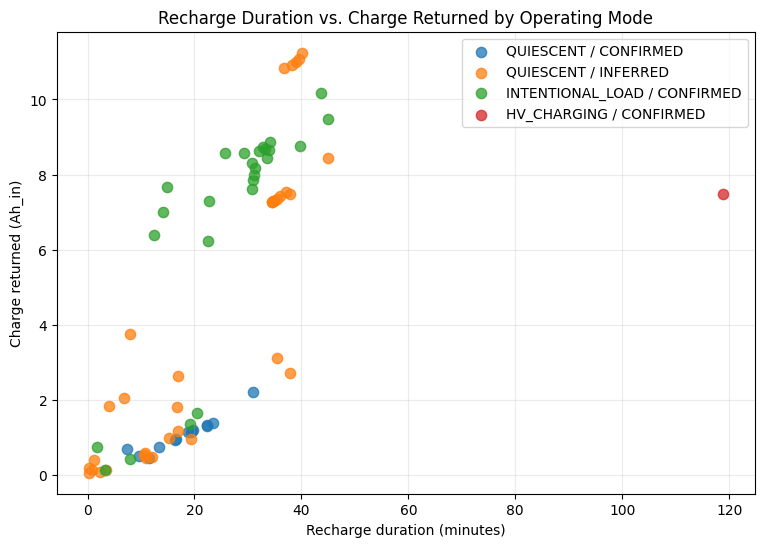

In [42]:
# ============================================================
# Recharge duration vs charge returned
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

plot_groups = [
    ("QUIESCENT", "CONFIRMED"),
    ("QUIESCENT", "INFERRED"),
    ("INTENTIONAL_LOAD", "CONFIRMED"),
    ("HV_CHARGING", "CONFIRMED"),
]

for mode, confidence in plot_groups:

    subset = df_all[
        (df_all["operating_mode"] == mode) &
        (df_all["mode_confidence"] == confidence)
    ]

    ax.scatter(
        subset["duration_s"] / 60,
        subset["Ah_in"],
        label=f"{mode} / {confidence}",
        alpha=0.75,
        s=55
    )

ax.set_xlabel("Recharge duration (minutes)")
ax.set_ylabel("Charge returned (Ah_in)")
ax.set_title(
    "Recharge Duration vs. Charge Returned by Operating Mode"
)

ax.grid(alpha=0.25)
ax.legend()

plt.show()

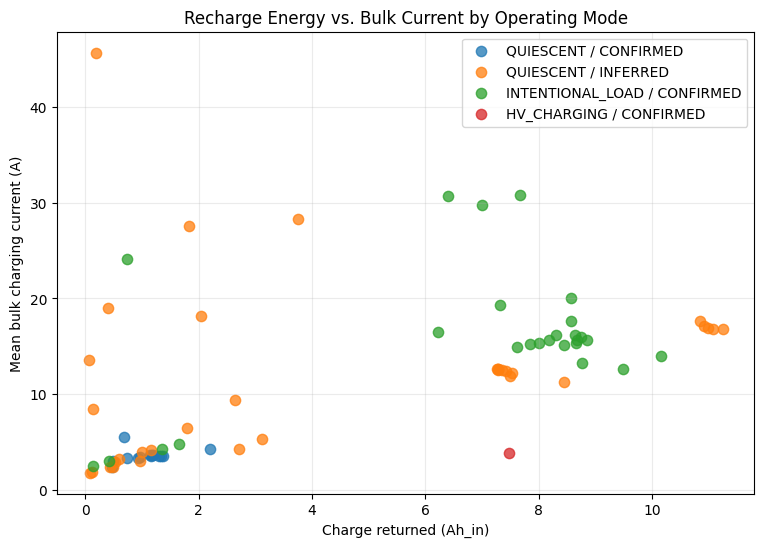

In [43]:
# ============================================================
# Charge returned vs bulk recharge current
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

for mode, confidence in plot_groups:

    subset = df_all[
        (df_all["operating_mode"] == mode) &
        (df_all["mode_confidence"] == confidence)
    ]

    ax.scatter(
        subset["Ah_in"],
        subset["I_bulk_mean"],
        label=f"{mode} / {confidence}",
        alpha=0.75,
        s=55
    )

ax.set_xlabel("Charge returned (Ah_in)")
ax.set_ylabel("Mean bulk charging current (A)")
ax.set_title(
    "Recharge Energy vs. Bulk Current by Operating Mode"
)

ax.grid(alpha=0.25)
ax.legend()

plt.show()

In [44]:
# ============================================================
# Recharge behavior by individual source log
# ============================================================

source_recharge_summary = (
    df_all
    .groupby([
        "source_file",
        "operating_mode",
        "mode_confidence"
    ])
    .agg(
        cycles=("cycle_id", "count"),

        median_Ah_in=("Ah_in", "median"),
        std_Ah_in=("Ah_in", "std"),

        median_duration_min=(
            "duration_s",
            lambda x: x.median() / 60
        ),

        median_bulk_current_A=(
            "I_bulk_mean",
            "median"
        )
    )
    .reset_index()
    .sort_values([
        "operating_mode",
        "median_Ah_in"
    ])
)

display(source_recharge_summary)

,source_file,operating_mode,mode_confidence,cycles,median_Ah_in,std_Ah_in,median_duration_min,median_bulk_current_A
11,12V_IBS_Charge_during_L2_HV_charning_after_IBS...,HV_CHARGING,CONFIRMED,1,7.481,NaN,118.817,3.775
0,12V IBS Full load 2025-08-20_22-17-18_L001_IBS...,INTENTIONAL_LOAD,CONFIRMED,5,6.995,3.402,22.550,16.522
4,12V IBS Full load 2025-08-20_22-17-18_L005_IBS...,INTENTIONAL_LOAD,CONFIRMED,5,7.612,3.643,14.900,14.865
3,12V IBS Full load 2025-08-20_22-17-18_L004_IBS...,INTENTIONAL_LOAD,CONFIRMED,4,7.921,0.374,31.092,15.495
2,12V IBS Full load 2025-08-20_22-17-18_L003_IBS...,INTENTIONAL_LOAD,CONFIRMED,4,8.469,4.218,31.417,14.684
5,12V IBS Full load 2025-08-20_22-17-18_L006_IBS...,INTENTIONAL_LOAD,CONFIRMED,4,8.609,3.526,29.792,15.434
1,12V IBS Full load 2025-08-20_22-17-18_L002_IBS...,INTENTIONAL_LOAD,CONFIRMED,4,8.620,3.651,31.017,15.802
16,IBS 2025-10-04_13-33-54_L006_IBS_only_cleaned.csv,QUIESCENT,INFERRED,2,0.421,0.025,6.158,10.682
22,IBS 2025-10-04_13-33-54_L012_IBS_only_cleaned.csv,QUIESCENT,INFERRED,1,0.488,NaN,12.133,2.352
8,12V Management IBS 1hr Reset 2025-06-29_09-32...,QUIESCENT,INFERRED,1,0.585,NaN,10.683,3.222


In [45]:
# ============================================================
# Within-source repeatability
# ============================================================

def coefficient_of_variation(series):
    mean = series.mean()

    if pd.isna(mean) or mean == 0:
        return np.nan

    return series.std() / abs(mean)


source_repeatability = (
    df_all
    .groupby([
        "source_file",
        "operating_mode",
        "mode_confidence"
    ])
    .agg(
        cycles=("cycle_id", "count"),

        Ah_in_cv=(
            "Ah_in",
            coefficient_of_variation
        ),

        duration_cv=(
            "duration_s",
            coefficient_of_variation
        ),

        bulk_current_cv=(
            "I_bulk_mean",
            coefficient_of_variation
        )
    )
    .reset_index()
)

# CV isn't meaningful for a single observation
source_repeatability = source_repeatability[
    source_repeatability["cycles"] >= 2
].copy()

display(
    source_repeatability.sort_values(
        "Ah_in_cv"
    )
)

,source_file,operating_mode,mode_confidence,cycles,Ah_in_cv,duration_cv,bulk_current_cv
3,12V IBS Full load 2025-08-20_22-17-18_L004_IBS...,INTENTIONAL_LOAD,CONFIRMED,4,0.048,0.144,0.118
16,IBS 2025-10-04_13-33-54_L006_IBS_only_cleaned.csv,QUIESCENT,INFERRED,2,0.059,1.120,1.105
12,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...,QUIESCENT,CONFIRMED,4,0.088,0.104,0.017
13,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...,QUIESCENT,CONFIRMED,5,0.237,0.341,0.236
9,12V_IBS_Charge_Discharge_after_IBS_00007_IBS_o...,QUIESCENT,INFERRED,9,0.365,0.374,0.689
10,12V_IBS_Charge_Discharge_after_IBS_Reset_00003...,QUIESCENT,INFERRED,6,0.438,0.276,0.363
5,12V IBS Full load 2025-08-20_22-17-18_L006_IBS...,INTENTIONAL_LOAD,CONFIRMED,4,0.509,0.232,0.465
0,12V IBS Full load 2025-08-20_22-17-18_L001_IBS...,INTENTIONAL_LOAD,CONFIRMED,5,0.533,0.717,0.362
1,12V IBS Full load 2025-08-20_22-17-18_L002_IBS...,INTENTIONAL_LOAD,CONFIRMED,4,0.534,0.230,0.460
4,12V IBS Full load 2025-08-20_22-17-18_L005_IBS...,INTENTIONAL_LOAD,CONFIRMED,5,0.565,0.676,0.643


In [46]:
# ============================================================
# Within-source repeatability
# Complete energy cycles only
# ============================================================

source_repeatability_complete = (
    df_discharge
    .groupby([
        "source_file",
        "operating_mode",
        "mode_confidence"
    ])
    .agg(
        cycles=("cycle_id", "count"),

        Ah_in_mean=("Ah_in", "mean"),
        Ah_in_cv=(
            "Ah_in",
            coefficient_of_variation
        ),

        duration_mean_s=("duration_s", "mean"),
        duration_cv=(
            "duration_s",
            coefficient_of_variation
        ),

        bulk_current_mean_A=("I_bulk_mean", "mean"),
        bulk_current_cv=(
            "I_bulk_mean",
            coefficient_of_variation
        )
    )
    .reset_index()
)

# CV requires multiple observations
source_repeatability_complete = (
    source_repeatability_complete[
        source_repeatability_complete["cycles"] >= 2
    ]
    .copy()
)

display(
    source_repeatability_complete.sort_values(
        ["operating_mode", "Ah_in_cv"]
    )
)

,source_file,operating_mode,mode_confidence,cycles,Ah_in_mean,Ah_in_cv,duration_mean_s,duration_cv,bulk_current_mean_A,bulk_current_cv
1,12V IBS Full load 2025-08-20_22-17-18_L002_IBS...,INTENTIONAL_LOAD,CONFIRMED,3,8.659,0.010,"1,905.667",0.070,16.400,0.064
5,12V IBS Full load 2025-08-20_22-17-18_L006_IBS...,INTENTIONAL_LOAD,CONFIRMED,3,8.691,0.017,"1,873.000",0.154,16.968,0.157
2,12V IBS Full load 2025-08-20_22-17-18_L003_IBS...,INTENTIONAL_LOAD,CONFIRMED,3,8.568,0.027,"2,050.667",0.141,15.186,0.111
3,12V IBS Full load 2025-08-20_22-17-18_L004_IBS...,INTENTIONAL_LOAD,CONFIRMED,3,7.716,0.047,"1,699.333",0.169,16.597,0.138
0,12V IBS Full load 2025-08-20_22-17-18_L001_IBS...,INTENTIONAL_LOAD,CONFIRMED,4,7.790,0.188,"1,729.500",0.466,18.488,0.415
4,12V IBS Full load 2025-08-20_22-17-18_L005_IBS...,INTENTIONAL_LOAD,CONFIRMED,4,7.962,0.198,"1,527.500",0.574,22.586,0.419
9,12V_IBS_Charge_Discharge_after_IBS_Reset_00003...,QUIESCENT,INFERRED,5,11.013,0.014,"2,323.400",0.033,17.058,0.021
10,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...,QUIESCENT,CONFIRMED,3,1.296,0.076,"1,312.333",0.090,3.534,0.015
11,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...,QUIESCENT,CONFIRMED,4,1.075,0.256,"1,027.500",0.389,4.031,0.249
8,12V_IBS_Charge_Discharge_after_IBS_00007_IBS_o...,QUIESCENT,INFERRED,8,6.448,0.393,"1,853.500",0.402,16.637,0.706


In [47]:
# ============================================================
# Confirmed intentional-load repeatability
# Complete energy cycles only
# ============================================================

intentional_repeatability = (
    source_repeatability_complete[
        (source_repeatability_complete["operating_mode"]
            == "INTENTIONAL_LOAD") &
        (source_repeatability_complete["mode_confidence"]
            == "CONFIRMED")
    ]
    .copy()
)

display(
    intentional_repeatability.sort_values(
        "Ah_in_mean"
    )
)

,source_file,operating_mode,mode_confidence,cycles,Ah_in_mean,Ah_in_cv,duration_mean_s,duration_cv,bulk_current_mean_A,bulk_current_cv
3,12V IBS Full load 2025-08-20_22-17-18_L004_IBS...,INTENTIONAL_LOAD,CONFIRMED,3,7.716,0.047,"1,699.333",0.169,16.597,0.138
0,12V IBS Full load 2025-08-20_22-17-18_L001_IBS...,INTENTIONAL_LOAD,CONFIRMED,4,7.790,0.188,"1,729.500",0.466,18.488,0.415
4,12V IBS Full load 2025-08-20_22-17-18_L005_IBS...,INTENTIONAL_LOAD,CONFIRMED,4,7.962,0.198,"1,527.500",0.574,22.586,0.419
2,12V IBS Full load 2025-08-20_22-17-18_L003_IBS...,INTENTIONAL_LOAD,CONFIRMED,3,8.568,0.027,"2,050.667",0.141,15.186,0.111
1,12V IBS Full load 2025-08-20_22-17-18_L002_IBS...,INTENTIONAL_LOAD,CONFIRMED,3,8.659,0.010,"1,905.667",0.070,16.400,0.064
5,12V IBS Full load 2025-08-20_22-17-18_L006_IBS...,INTENTIONAL_LOAD,CONFIRMED,3,8.691,0.017,"1,873.000",0.154,16.968,0.157


### 💡 Normal-Behavior Repeatability

Analysis of complete energy cycles shows that known-normal vehicle
behavior can produce highly repeatable recharge signatures when the
underlying operating context remains stable.

Four of the six confirmed intentional-load logs (L002, L003, L004,
and L006) show particularly consistent charge-return behavior, with
within-log coefficients of variation of approximately 1–5% for
`Ah_in`.

The remaining intentional-load logs show greater variation in recharge
duration and bulk current. Because the specific intentional electrical
loads were not documented, this variation cannot be attributed to a
specific subsystem or load condition.

Confirmed quiescent sleep logs occupy a substantially lower recharge
range than the intentional-load tests, but repeatability varies by
feature and source log.

One inferred-quiescent dataset exhibits an extremely repeatable
high-charge signature that does not resemble the confirmed quiescent
sleep data. Because its original operating condition cannot be
independently verified, it is retained as inferred rather than
reclassified based on its measured behavior.

These results support two important principles:

> **Normal vehicle behavior can be repeatable without being represented
> by one global normal range.**

and

> **Unexpected behavior relative to an assumed Operating Mode should
> trigger additional evidence gathering, not automatically be classified
> as a vehicle fault.**

## 5. Feature Selection & Behavioral Representation

Following exploratory analysis, the feature set will be reduced to a smaller number of physically interpretable and sufficiently independent variables.

The goal is not to maximize the number of features supplied to a model.

The goal is to create a compact representation of **vehicle energy behavior** that preserves meaningful information while avoiding:

- Redundant features
- Stale or unobservable measurements
- Data leakage
- Features without clear physical interpretation
- Operating-state artifacts incorrectly interpreted as anomalies

### Candidate Behavioral Dimensions

The final feature set is expected to represent several dimensions:

- **Operating Context** — what the vehicle is expected to be doing
- **Timing** — duration between relevant energy events
- **Energy Demand** — energy removed from or returned to the LV battery
- **Electrical Response** — voltage/current behavior
- **Recharge Behavior** — how the vehicle restores LV battery energy
- **Wake/Sleep Behavior** — vehicle/network activity while parked
- **Signal Quality** — whether the underlying telemetry is observable and trustworthy

### 💡 Design Principle

> **Feature engineering should preserve vehicle physics and operating context before introducing model complexity.**

In [48]:
# ============================================================
# Recharge feature correlation analysis
# ============================================================

recharge_features = [
    "Ah_in",
    "duration_s",
    "I_bulk_mean",
    "V_peak_charge",
    "V_mean_charge",
    "V_tail_mean",
]

recharge_corr = (
    df_all[recharge_features]
    .corr()
)

display(recharge_corr.round(3))

,Ah_in,duration_s,I_bulk_mean,V_peak_charge,V_mean_charge,V_tail_mean
Ah_in,1.000,0.677,0.470,0.244,-0.354,0.245
duration_s,0.677,1.000,-0.029,0.428,0.116,0.415
I_bulk_mean,0.470,-0.029,1.000,-0.680,-0.962,-0.656
V_peak_charge,0.244,0.428,-0.680,1.000,0.781,0.988
V_mean_charge,-0.354,0.116,-0.962,0.781,1.000,0.779
V_tail_mean,0.245,0.415,-0.656,0.988,0.779,1.000


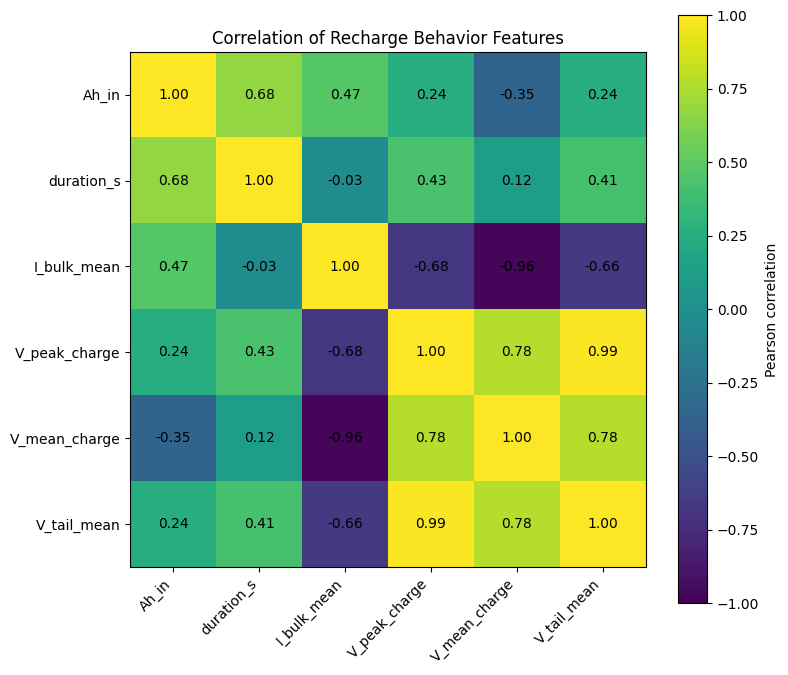

In [49]:
# ============================================================
# Recharge feature correlation heatmap
# ============================================================

fig, ax = plt.subplots(figsize=(8, 7))

im = ax.imshow(
    recharge_corr,
    vmin=-1,
    vmax=1
)

ax.set_xticks(
    range(len(recharge_features))
)

ax.set_yticks(
    range(len(recharge_features))
)

ax.set_xticklabels(
    recharge_features,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(
    recharge_features
)

# Display correlation values
for i in range(len(recharge_features)):
    for j in range(len(recharge_features)):
        ax.text(
            j,
            i,
            f"{recharge_corr.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

ax.set_title(
    "Correlation of Recharge Behavior Features"
)

fig.colorbar(
    im,
    ax=ax,
    label="Pearson correlation"
)

plt.tight_layout()
plt.show()

In [50]:
# ============================================================
# Identify highly correlated recharge feature pairs
# ============================================================

corr_pairs = []

for i in range(len(recharge_features)):
    for j in range(i + 1, len(recharge_features)):

        feature_1 = recharge_features[i]
        feature_2 = recharge_features[j]

        correlation = recharge_corr.loc[
            feature_1,
            feature_2
        ]

        corr_pairs.append({
            "feature_1": feature_1,
            "feature_2": feature_2,
            "correlation": correlation,
            "abs_correlation": abs(correlation),
        })

corr_pairs_df = (
    pd.DataFrame(corr_pairs)
    .sort_values(
        "abs_correlation",
        ascending=False
    )
)

display(
    corr_pairs_df[
        [
            "feature_1",
            "feature_2",
            "correlation"
        ]
    ].round(3)
)

,feature_1,feature_2,correlation
13,V_peak_charge,V_tail_mean,0.988
10,I_bulk_mean,V_mean_charge,-0.962
12,V_peak_charge,V_mean_charge,0.781
14,V_mean_charge,V_tail_mean,0.779
9,I_bulk_mean,V_peak_charge,-0.680
0,Ah_in,duration_s,0.677
11,I_bulk_mean,V_tail_mean,-0.656
1,Ah_in,I_bulk_mean,0.470
6,duration_s,V_peak_charge,0.428
8,duration_s,V_tail_mean,0.415


### Candidate Behavioral Representation

Rather than using all available telemetry-derived features, the initial
Vehicle Service Intelligence model should use a compact set of features
that represent distinct physical aspects of an LV energy cycle.

The initial behavioral dimensions are:

| Behavioral Dimension | Candidate Feature | Physical Interpretation |
|---|---|---|
| Charge Demand | `Ah_in` | Amount of charge subsequently returned to the LV battery |
| Recharge Timing | `duration_s` | Duration of the LV recharge event |
| Recharge Intensity | `I_bulk_mean` | Typical charging current during the bulk portion of recharge |
| Voltage Response | TBD | Representative voltage behavior during recharge |
| Operating Context | `operating_mode` | Known or inferred vehicle Operating Mode |
| Context Confidence | `mode_confidence` | Confidence in the Operating Mode metadata |

Additional parked/discharge features may be introduced only when their
underlying telemetry is sufficiently observable.

### Feature-Selection Principle

Feature selection is based on three criteria:

1. **Physical interpretability** — the feature represents a meaningful vehicle behavior.
2. **Independent information** — the feature adds information not already captured by another feature.
3. **Signal trustworthiness** — the underlying measurement is sufficiently observable for the Operating Mode being analyzed.

The objective is not to maximize model inputs.

> **The objective is to represent vehicle behavior with the smallest set of trustworthy, physically meaningful dimensions.**

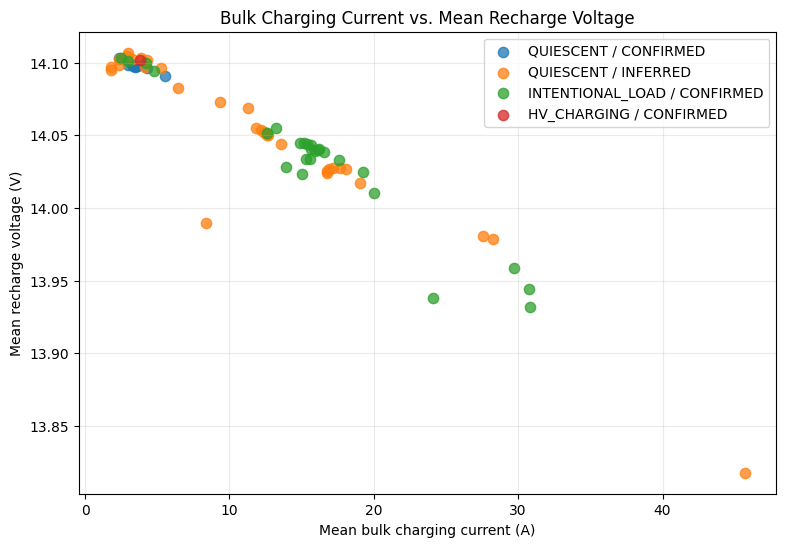

In [51]:
# ============================================================
# Investigate bulk current vs mean recharge voltage
# ============================================================

fig, ax = plt.subplots(figsize=(9, 6))

plot_groups = [
    ("QUIESCENT", "CONFIRMED"),
    ("QUIESCENT", "INFERRED"),
    ("INTENTIONAL_LOAD", "CONFIRMED"),
    ("HV_CHARGING", "CONFIRMED"),
]

for mode, confidence in plot_groups:

    subset = df_all[
        (df_all["operating_mode"] == mode) &
        (df_all["mode_confidence"] == confidence)
    ]

    ax.scatter(
        subset["I_bulk_mean"],
        subset["V_mean_charge"],
        label=f"{mode} / {confidence}",
        alpha=0.75,
        s=55
    )

ax.set_xlabel("Mean bulk charging current (A)")
ax.set_ylabel("Mean recharge voltage (V)")
ax.set_title(
    "Bulk Charging Current vs. Mean Recharge Voltage"
)

ax.grid(alpha=0.25)
ax.legend()

plt.show()

### 💡 Recharge Feature Correlation

Correlation analysis shows that several recharge features contain
substantial overlapping information.

`V_peak_charge` and `V_tail_mean` are almost perfectly correlated
(r = 0.988), indicating that both variables provide nearly the same
information about recharge voltage behavior in this dataset.

`I_bulk_mean` and `V_mean_charge` are strongly negatively correlated
(r = -0.962). Visual inspection shows that this relationship persists
across Operating Modes rather than being produced solely by differences
between mode populations.

Because `I_bulk_mean` describes the early/bulk portion of recharge while
`V_mean_charge` averages voltage across the complete detected recharge
event, the relationship may partly reflect recharge-cycle shape and
feature definition. A causal physical interpretation is not assigned
at this stage.

For behavioral modeling, `V_mean_charge` is excluded from the initial
feature set because it contributes limited independent information once
bulk charging current is represented.

By comparison, recharge duration and bulk charging current are
essentially uncorrelated (r = -0.029), indicating that they represent
different dimensions of recharge behavior.

`Ah_in` shows moderate relationships with both recharge duration
(r = 0.677) and bulk current (r = 0.470), consistent with charge
returned being influenced by both the duration and intensity of the
recharge event.

### Initial Recharge Feature Set

Based on physical interpretability, signal observability, and feature
redundancy, the initial candidate representation is:

- `Ah_in` — charge demand
- `duration_s` — recharge timing
- `I_bulk_mean` — recharge intensity
- `V_peak_charge` — voltage response

`V_tail_mean` is initially excluded because of its near-perfect
correlation with `V_peak_charge`.

`V_mean_charge` is held out pending further investigation of its strong
relationship with bulk charging current.

Operating Mode and mode confidence are retained as contextual metadata
rather than automatically treated as numerical model inputs.

### Feature Trust Matrix

Feature selection for Vehicle Service Intelligence must consider more
than statistical correlation.

A feature may be physically meaningful but unsuitable for modeling if
the underlying vehicle signal is not continuously observable under the
Operating Mode being analyzed.

The Feature Trust Matrix evaluates candidate features using four
questions:

1. **What physical behavior does the feature represent?**
2. **Is the underlying signal observable when the feature is calculated?**
3. **Does the feature provide sufficiently independent information?**
4. **Can the feature be interpreted consistently across Operating Modes?**

Features are assigned one of three initial modeling states:

- **USE** — sufficiently trustworthy and interpretable for the initial model
- **EVALUATE** — potentially useful but requires additional validation
- **HOLD** — excluded from the initial model because of observability,
  redundancy, or interpretation concerns

These classifications apply to the current dataset and analysis.
They are not claims that a feature would be unsuitable in a production
vehicle implementation with explicit signal-freshness metadata.

In [52]:
# ============================================================
# Feature Trust Matrix
# ============================================================

feature_trust = pd.DataFrame([
    {
        "feature": "Ah_in",
        "behavioral_dimension": "Charge demand",
        "physical_interpretation": "Charge returned to LV battery during recharge",
        "observability": "HIGH",
        "independence": "MODERATE",
        "cross_mode_interpretation": "GOOD",
        "initial_status": "USE",
        "reason": "Observable during recharge; physically interpretable; available for all 75 cycles."
    },
    {
        "feature": "duration_s",
        "behavioral_dimension": "Recharge timing",
        "physical_interpretation": "Duration of detected LV recharge event",
        "observability": "HIGH",
        "independence": "GOOD",
        "cross_mode_interpretation": "GOOD",
        "initial_status": "USE",
        "reason": "Observable for all recharge events and nearly independent of bulk current."
    },
    {
        "feature": "I_bulk_mean",
        "behavioral_dimension": "Recharge intensity",
        "physical_interpretation": "Mean current during early/bulk recharge",
        "observability": "HIGH",
        "independence": "GOOD",
        "cross_mode_interpretation": "GOOD",
        "initial_status": "USE",
        "reason": "Observable during recharge; distinguishes recharge intensity; adds information beyond duration."
    },
    {
        "feature": "V_peak_charge",
        "behavioral_dimension": "Voltage response",
        "physical_interpretation": "Peak LV battery voltage during recharge",
        "observability": "HIGH",
        "independence": "MODERATE",
        "cross_mode_interpretation": "GOOD",
        "initial_status": "USE",
        "reason": "Observable and physically meaningful; retained initially to represent voltage response."
    },
    {
        "feature": "V_mean_charge",
        "behavioral_dimension": "Voltage response",
        "physical_interpretation": "Mean battery voltage across detected recharge event",
        "observability": "HIGH",
        "independence": "LOW",
        "cross_mode_interpretation": "GOOD",
        "initial_status": "HOLD",
        "reason": "Strongly correlated with I_bulk_mean (r = -0.962); limited independent information."
    },
    {
        "feature": "V_tail_mean",
        "behavioral_dimension": "Voltage response",
        "physical_interpretation": "Mean battery voltage near end of recharge",
        "observability": "HIGH",
        "independence": "LOW",
        "cross_mode_interpretation": "GOOD",
        "initial_status": "HOLD",
        "reason": "Nearly perfectly correlated with V_peak_charge (r = 0.988)."
    },
    {
        "feature": "discharge_duration_s",
        "behavioral_dimension": "Parked interval timing",
        "physical_interpretation": "Elapsed time between successive recharge events",
        "observability": "MODERATE",
        "independence": "GOOD",
        "cross_mode_interpretation": "GOOD",
        "initial_status": "EVALUATE",
        "reason": "Does not require continuous current measurement, but only available for cycles with complete preceding history."
    },
    {
        "feature": "Ah_out_prev",
        "behavioral_dimension": "Apparent discharge demand",
        "physical_interpretation": "Integrated apparent battery discharge before recharge",
        "observability": "CONDITIONAL",
        "independence": "MODERATE",
        "cross_mode_interpretation": "CONDITIONAL",
        "initial_status": "HOLD",
        "reason": "Can be physically valid while IBS is observable but severely overstated when stale current is forward-filled during sleep."
    },
    {
        "feature": "discharge_Ah_per_hr",
        "behavioral_dimension": "Apparent discharge rate",
        "physical_interpretation": "Apparent discharged Ah normalized by elapsed interval",
        "observability": "CONDITIONAL",
        "independence": "LOW",
        "cross_mode_interpretation": "CONDITIONAL",
        "initial_status": "HOLD",
        "reason": "Depends on Ah_out_prev and therefore inherits stale-current observability risk."
    },
    {
        "feature": "discharge_I_mean",
        "behavioral_dimension": "Discharge intensity",
        "physical_interpretation": "Mean magnitude of IBS current during apparent discharge samples",
        "observability": "CONDITIONAL",
        "independence": "LOW",
        "cross_mode_interpretation": "CONDITIONAL",
        "initial_status": "HOLD",
        "reason": "Current may be forward-filled when IBS stops transmitting; cannot be assumed continuously observed during sleep."
    },
    {
        "feature": "discharge_I_p90",
        "behavioral_dimension": "Discharge intensity",
        "physical_interpretation": "90th-percentile apparent IBS discharge current",
        "observability": "CONDITIONAL",
        "independence": "LOW",
        "cross_mode_interpretation": "CONDITIONAL",
        "initial_status": "HOLD",
        "reason": "Same signal-observability limitation as discharge_I_mean and strongly related to discharge-current magnitude."
    },
    {
        "feature": "discharge_V_drop",
        "behavioral_dimension": "Discharge voltage response",
        "physical_interpretation": "Observed voltage decrease across discharge samples",
        "observability": "CONDITIONAL",
        "independence": "MODERATE",
        "cross_mode_interpretation": "CONDITIONAL",
        "initial_status": "EVALUATE",
        "reason": "Physically meaningful, but voltage freshness during deep sleep has not yet been independently validated."
    },
    {
        "feature": "discharge_V_decay_per_hr",
        "behavioral_dimension": "Discharge voltage response",
        "physical_interpretation": "Observed voltage decrease normalized by elapsed interval",
        "observability": "CONDITIONAL",
        "independence": "MODERATE",
        "cross_mode_interpretation": "CONDITIONAL",
        "initial_status": "EVALUATE",
        "reason": "Potentially useful but depends on both voltage observability and interval definition."
    }
])

display(feature_trust)

,feature,behavioral_dimension,physical_interpretation,observability,independence,cross_mode_interpretation,initial_status,reason
0,Ah_in,Charge demand,Charge returned to LV battery during recharge,HIGH,MODERATE,GOOD,USE,Observable during recharge; physically interpr...
1,duration_s,Recharge timing,Duration of detected LV recharge event,HIGH,GOOD,GOOD,USE,Observable for all recharge events and nearly ...
2,I_bulk_mean,Recharge intensity,Mean current during early/bulk recharge,HIGH,GOOD,GOOD,USE,Observable during recharge; distinguishes rech...
3,V_peak_charge,Voltage response,Peak LV battery voltage during recharge,HIGH,MODERATE,GOOD,USE,Observable and physically meaningful; retained...
4,V_mean_charge,Voltage response,Mean battery voltage across detected recharge ...,HIGH,LOW,GOOD,HOLD,Strongly correlated with I_bulk_mean (r = -0.9...
5,V_tail_mean,Voltage response,Mean battery voltage near end of recharge,HIGH,LOW,GOOD,HOLD,Nearly perfectly correlated with V_peak_charge...
6,discharge_duration_s,Parked interval timing,Elapsed time between successive recharge events,MODERATE,GOOD,GOOD,EVALUATE,Does not require continuous current measuremen...
7,Ah_out_prev,Apparent discharge demand,Integrated apparent battery discharge before r...,CONDITIONAL,MODERATE,CONDITIONAL,HOLD,Can be physically valid while IBS is observabl...
8,discharge_Ah_per_hr,Apparent discharge rate,Apparent discharged Ah normalized by elapsed i...,CONDITIONAL,LOW,CONDITIONAL,HOLD,Depends on Ah_out_prev and therefore inherits ...
9,discharge_I_mean,Discharge intensity,Mean magnitude of IBS current during apparent ...,CONDITIONAL,LOW,CONDITIONAL,HOLD,Current may be forward-filled when IBS stops t...


In [53]:
# ============================================================
# Initial feature-selection summary
# ============================================================

feature_selection_summary = (
    feature_trust[
        [
            "feature",
            "behavioral_dimension",
            "observability",
            "independence",
            "initial_status"
        ]
    ]
    .sort_values(
        ["initial_status", "behavioral_dimension"]
    )
)

display(feature_selection_summary)

,feature,behavioral_dimension,observability,independence,initial_status
11,discharge_V_drop,Discharge voltage response,CONDITIONAL,MODERATE,EVALUATE
12,discharge_V_decay_per_hr,Discharge voltage response,CONDITIONAL,MODERATE,EVALUATE
6,discharge_duration_s,Parked interval timing,MODERATE,GOOD,EVALUATE
7,Ah_out_prev,Apparent discharge demand,CONDITIONAL,MODERATE,HOLD
8,discharge_Ah_per_hr,Apparent discharge rate,CONDITIONAL,LOW,HOLD
9,discharge_I_mean,Discharge intensity,CONDITIONAL,LOW,HOLD
10,discharge_I_p90,Discharge intensity,CONDITIONAL,LOW,HOLD
4,V_mean_charge,Voltage response,HIGH,LOW,HOLD
5,V_tail_mean,Voltage response,HIGH,LOW,HOLD
0,Ah_in,Charge demand,HIGH,MODERATE,USE


### 💡 Feature-Selection Result

The initial behavioral representation is intentionally conservative.

Four recharge features are selected for the first normal-behavior model:

- `Ah_in` — charge demand
- `duration_s` — recharge timing
- `I_bulk_mean` — recharge intensity
- `V_peak_charge` — voltage response

These features are observable during all detected recharge events and
represent distinct, physically interpretable aspects of vehicle behavior.

Several discharge features remain highly relevant but are not admitted
to the initial model because their validity depends on signal
observability during vehicle sleep.

This distinction is important:

> **A useful feature should not be excluded because the physical concept
> is weak; it should be excluded when the available telemetry cannot
> support the interpretation reliably.**

In a production implementation with explicit signal timestamps,
freshness indicators, and network-state information, several currently
held discharge features could be reconsidered.

Operating Mode and mode confidence remain contextual metadata used to
interpret model behavior rather than continuous numerical features.

The initial model therefore begins with a deliberately small,
high-confidence behavioral representation before additional telemetry
is introduced.

## 6. Normal-Behavior Modeling

The project does not currently contain labeled failure examples.

Therefore, the first modeling objective is not to predict failure.

Instead, the objective is to characterize the envelope of **known-normal vehicle behavior** and determine whether a new observation is consistent with that behavior.

Potential approaches include:

- Statistical operating envelopes
- Principal Component Analysis (PCA) and multivariate distance
- Clustering
- Isolation Forest
- Other unsupervised or one-class anomaly-detection methods

The modeling approach will be selected based on the structure observed during exploratory analysis rather than selecting an algorithm in advance.

### Context-Aware Normality

A statistically unusual observation is not necessarily an operational anomaly.

For example, high LV battery discharge may be completely normal when a known high electrical load is active.

Therefore:

> **Anomaly = behavior that is inconsistent with the expected operating context, not simply behavior that is statistically rare.**

### 💡 Objective

Develop an interpretable model of expected parked-energy behavior that can serve as the baseline for subsequent anomaly detection.

In [54]:
# ============================================================
# Initial normal-behavior feature set
# ============================================================

model_features = [
    "Ah_in",
    "duration_s",
    "I_bulk_mean",
    "V_peak_charge",
]

model_metadata = [
    "cycle_id",
    "source_file",
    "operating_mode",
    "mode_confidence",
]

df_model = df_all[
    model_metadata + model_features
].copy()

print("Initial modeling dataset")
print("------------------------")
print(f"Observations: {len(df_model)}")
print(f"Features:     {len(model_features)}")

display(
    df_model[
        model_features
    ].describe().T
)

Initial modeling dataset
------------------------
Observations: 75
Features:     4


,count,mean,std,min,25%,50%,75%,max
Ah_in,75.000,4.605,3.824,0.056,0.965,3.121,8.084,11.244
duration_s,75.000,"1,440.640","1,017.577",14.000,739.000,"1,345.000","2,069.000","7,129.000"
I_bulk_mean,75.000,11.667,8.704,1.773,3.574,12.468,16.159,45.691
V_peak_charge,75.000,14.097,0.036,13.889,14.106,14.108,14.110,14.120


In [55]:
# ============================================================
# Standardize trusted behavioral features
# ============================================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    df_model[model_features]
)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=model_features,
    index=df_model.index
)

display(
    X_scaled_df.describe().round(3)
)

,Ah_in,duration_s,I_bulk_mean,V_peak_charge
count,75.000,75.000,75.000,75.000
mean,0.000,-0.000,0.000,-0.000
std,1.007,1.007,1.007,1.007
min,-1.197,-1.411,-1.144,-5.861
25%,-0.958,-0.694,-0.936,0.249
50%,-0.391,-0.095,0.093,0.306
75%,0.916,0.622,0.520,0.348
max,1.748,5.628,3.935,0.644


In [56]:
# ============================================================
# Principal Component Analysis
# ============================================================

from sklearn.decomposition import PCA

pca = PCA()

X_pca = pca.fit_transform(
    X_scaled
)

explained_variance = pd.DataFrame({
    "principal_component": [
        f"PC{i+1}"
        for i in range(len(model_features))
    ],
    "explained_variance_ratio":
        pca.explained_variance_ratio_,
})

explained_variance[
    "cumulative_variance"
] = explained_variance[
    "explained_variance_ratio"
].cumsum()

display(
    explained_variance.round(3)
)

,principal_component,explained_variance_ratio,cumulative_variance
0,PC1,0.483,0.483
1,PC2,0.428,0.911
2,PC3,0.081,0.992
3,PC4,0.008,1.000


In [57]:
# ============================================================
# PCA feature loadings
# ============================================================

pca_loadings = pd.DataFrame(
    pca.components_.T,
    index=model_features,
    columns=[
        f"PC{i+1}"
        for i in range(len(model_features))
    ]
)

display(
    pca_loadings.round(3)
)

,PC1,PC2,PC3,PC4
Ah_in,0.531,0.477,-0.413,-0.565
duration_s,0.638,0.152,0.730,0.194
I_bulk_mean,-0.145,0.739,-0.194,0.629
V_peak_charge,0.538,-0.451,-0.509,0.498


### 💡 PCA Behavioral Representation

Principal Component Analysis was applied to the four standardized
trusted recharge features:

- `Ah_in`
- `duration_s`
- `I_bulk_mean`
- `V_peak_charge`

The first two principal components explain **91.1% of the total feature
variance**, indicating that the four-dimensional recharge behavior can
be represented effectively in two dimensions for exploratory analysis.

**PC1 (48.3%)** is influenced most strongly by recharge duration, with
additional positive contributions from charge returned and peak recharge
voltage. It is interpreted here as an approximate **recharge
magnitude/timing dimension**.

**PC2 (42.8%)** is dominated by bulk charging current, with additional
contributions from charge returned and an opposing contribution from
peak recharge voltage. It is interpreted here as an approximate
**recharge intensity/profile dimension**.

These labels are descriptive interpretations based on PCA loadings.
The principal components are statistical combinations of the original
features rather than direct physical measurements.

Importantly, Operating Mode and mode confidence were **not used to
construct the PCA components**. They are applied only after PCA for
interpretation of the resulting behavioral space.

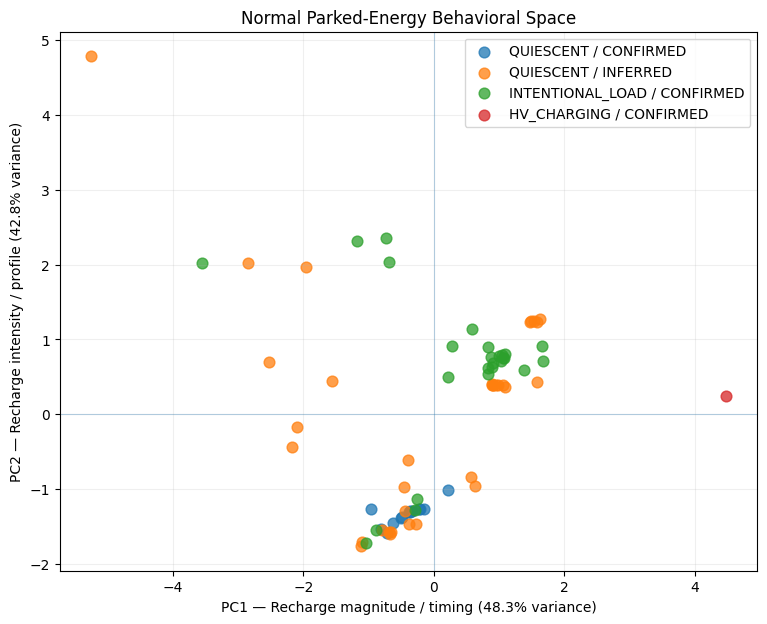

In [58]:
# ============================================================
# PCA behavioral map by Operating Mode
# ============================================================

df_pca = df_model.copy()

df_pca["PC1"] = X_pca[:, 0]
df_pca["PC2"] = X_pca[:, 1]

fig, ax = plt.subplots(figsize=(9, 7))

plot_groups = [
    ("QUIESCENT", "CONFIRMED"),
    ("QUIESCENT", "INFERRED"),
    ("INTENTIONAL_LOAD", "CONFIRMED"),
    ("HV_CHARGING", "CONFIRMED"),
]

for mode, confidence in plot_groups:

    subset = df_pca[
        (df_pca["operating_mode"] == mode) &
        (df_pca["mode_confidence"] == confidence)
    ]

    ax.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"{mode} / {confidence}",
        alpha=0.75,
        s=60
    )

ax.axhline(
    0,
    linewidth=0.8,
    alpha=0.3
)

ax.axvline(
    0,
    linewidth=0.8,
    alpha=0.3
)

ax.set_xlabel(
    "PC1 — Recharge magnitude / timing "
    "(48.3% variance)"
)

ax.set_ylabel(
    "PC2 — Recharge intensity / profile "
    "(42.8% variance)"
)

ax.set_title(
    "Normal Parked-Energy Behavioral Space"
)

ax.grid(alpha=0.20)
ax.legend()

plt.show()

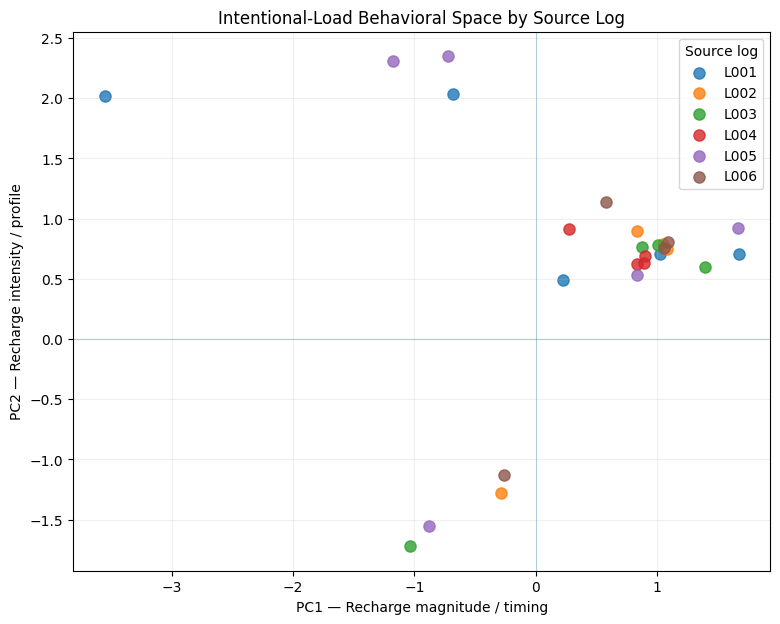

In [59]:
# ============================================================
# PCA behavioral map
# Confirmed intentional-load source logs
# ============================================================

df_pca_load = df_pca[
    (df_pca["operating_mode"] == "INTENTIONAL_LOAD") &
    (df_pca["mode_confidence"] == "CONFIRMED")
].copy()

fig, ax = plt.subplots(figsize=(9, 7))

for source_file, subset in df_pca_load.groupby("source_file"):

    # Extract L001, L002, etc. for cleaner legend
    label = source_file

    for log_id in [
        "L001", "L002", "L003",
        "L004", "L005", "L006"
    ]:
        if log_id in source_file:
            label = log_id
            break

    ax.scatter(
        subset["PC1"],
        subset["PC2"],
        label=label,
        alpha=0.80,
        s=65
    )

ax.axhline(0, linewidth=0.8, alpha=0.3)
ax.axvline(0, linewidth=0.8, alpha=0.3)

ax.set_xlabel(
    "PC1 — Recharge magnitude / timing"
)

ax.set_ylabel(
    "PC2 — Recharge intensity / profile"
)

ax.set_title(
    "Intentional-Load Behavioral Space by Source Log"
)

ax.grid(alpha=0.20)
ax.legend(title="Source log")

plt.show()

### 💡 PCA Behavioral-Space Findings

The first two principal components retain 91.1% of the variance in the
four-feature trusted recharge representation.

Operating Mode was not used to construct the PCA components. Mode and
confidence labels were applied only after dimensionality reduction for
interpretation.

The confirmed quiescent sleep cycles occupy a relatively concentrated
region of the behavioral space, indicating that known-normal quiescent
behavior has a recognizable multivariate recharge signature.

Most confirmed intentional-load observations occupy a different region,
although overlap exists. Therefore, recharge behavior alone should not
be interpreted as a deterministic classifier of Operating Mode.

The inferred-quiescent observations span a much broader portion of the
behavioral space. This is consistent with uncertainty in the original
test metadata and reinforces the decision not to use inferred Operating
Modes as ground-truth labels.

Within the confirmed intentional-load population, most observations
from L001–L006 occupy a common region, while several observations lie
well outside that cluster. Because the specific test conditions and
starting states are not fully documented, these observations are
retained rather than classified as abnormal.

These findings support the use of a **behavioral envelope** rather than
a single electrical threshold for representing expected vehicle
behavior.

In [60]:
# ============================================================
# Confirmed quiescent behavioral baseline
# ============================================================

df_quiescent = df_model[
    (df_model["operating_mode"] == "QUIESCENT") &
    (df_model["mode_confidence"] == "CONFIRMED")
].copy()

print("Confirmed quiescent baseline")
print("----------------------------")
print(f"Cycles:       {len(df_quiescent)}")
print(f"Source logs:  {df_quiescent['source_file'].nunique()}")

display(
    df_quiescent[
        model_features
    ].describe().T.round(3)
)

Confirmed quiescent baseline
----------------------------
Cycles:       14
Source logs:  3


,count,mean,std,min,25%,50%,75%,max
Ah_in,14.000,1.079,0.441,0.461,0.784,1.147,1.274,2.200
duration_s,14.000,"1,076.714",369.874,440.000,844.000,"1,144.000","1,298.250","1,852.000"
I_bulk_mean,14.000,3.574,0.694,2.374,3.372,3.509,3.580,5.533
V_peak_charge,14.000,14.108,0.001,14.105,14.108,14.108,14.108,14.109


In [61]:
# ============================================================
# Robust quiescent baseline statistics
# ============================================================

quiescent_baseline_stats = []

for feature in model_features:

    values = df_quiescent[feature].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)

    quiescent_baseline_stats.append({
        "feature": feature,
        "count": len(values),
        "mean": values.mean(),
        "std": values.std(),
        "median": values.median(),
        "q1": q1,
        "q3": q3,
        "iqr": q3 - q1,
        "min": values.min(),
        "max": values.max(),
    })

quiescent_baseline_stats = pd.DataFrame(
    quiescent_baseline_stats
)

display(
    quiescent_baseline_stats.round(3)
)

,feature,count,mean,std,median,q1,q3,iqr,min,max
0,Ah_in,14,1.079,0.441,1.147,0.784,1.274,0.491,0.461,2.200
1,duration_s,14,"1,076.714",369.874,"1,144.000",844.000,"1,298.250",454.250,440.000,"1,852.000"
2,I_bulk_mean,14,3.574,0.694,3.509,3.372,3.580,0.209,2.374,5.533
3,V_peak_charge,14,14.108,0.001,14.108,14.108,14.108,0.000,14.105,14.109


In [66]:
# ============================================================
# Assign simple source labels to confirmed quiescent logs
# ============================================================

quiescent_sources = (
    df_quiescent["source_file"]
    .drop_duplicates()
    .tolist()
)

source_map = {
    source: f"Sleep Log {i+1}"
    for i, source in enumerate(quiescent_sources)
}

df_quiescent["source_label"] = (
    df_quiescent["source_file"]
    .map(source_map)
)

display(
    df_quiescent[
        [
            "source_label",
            "source_file",
            "cycle_id"
        ]
    ]
)

,source_label,source_file,cycle_id
24,Sleep Log 1,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...
25,Sleep Log 1,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...
26,Sleep Log 1,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...
27,Sleep Log 1,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...
28,Sleep Log 1,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...
29,Sleep Log 2,12V_LIN_Normal_Dischare_12Hrs_Vehicle_sleep-Ch...,12V_LIN_Normal_Dischare_12Hrs_Vehicle_sleep-Ch...
30,Sleep Log 2,12V_LIN_Normal_Dischare_12Hrs_Vehicle_sleep-Ch...,12V_LIN_Normal_Dischare_12Hrs_Vehicle_sleep-Ch...
31,Sleep Log 2,12V_LIN_Normal_Dischare_12Hrs_Vehicle_sleep-Ch...,12V_LIN_Normal_Dischare_12Hrs_Vehicle_sleep-Ch...
32,Sleep Log 2,12V_LIN_Normal_Dischare_12Hrs_Vehicle_sleep-Ch...,12V_LIN_Normal_Dischare_12Hrs_Vehicle_sleep-Ch...
33,Sleep Log 2,12V_LIN_Normal_Dischare_12Hrs_Vehicle_sleep-Ch...,12V_LIN_Normal_Dischare_12Hrs_Vehicle_sleep-Ch...


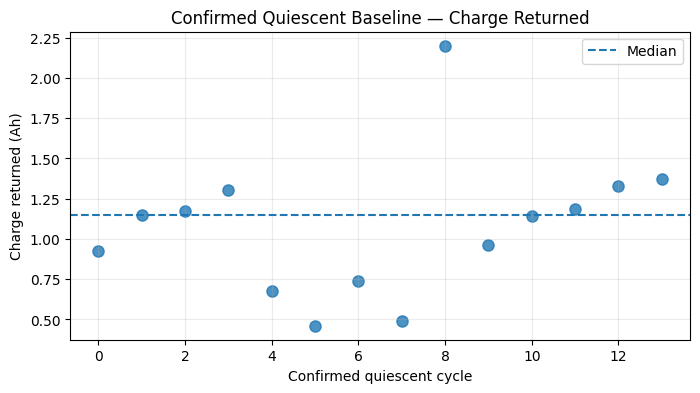

In [67]:
# ============================================================
# Confirmed quiescent baseline — Ah_in
# ============================================================

fig, ax = plt.subplots(figsize=(8, 4))

ax.scatter(
    range(len(df_quiescent)),
    df_quiescent["Ah_in"],
    s=65,
    alpha=0.8
)

ax.axhline(
    df_quiescent["Ah_in"].median(),
    linestyle="--",
    linewidth=1.5,
    label="Median"
)

ax.set_xlabel("Confirmed quiescent cycle")
ax.set_ylabel("Charge returned (Ah)")
ax.set_title("Confirmed Quiescent Baseline — Charge Returned")

ax.grid(alpha=0.25)
ax.legend()

plt.show()

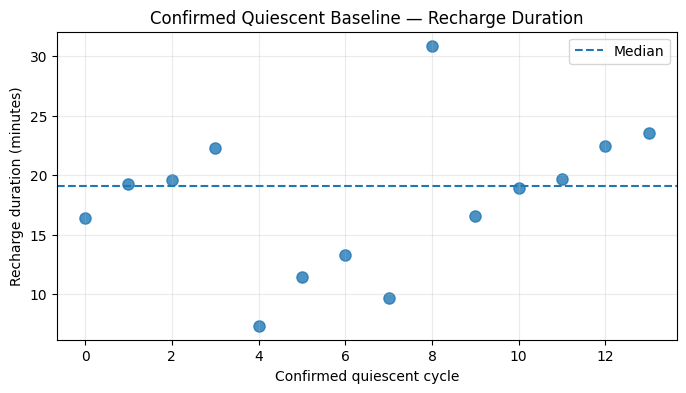

In [68]:
# ============================================================
# Confirmed quiescent baseline — recharge duration
# ============================================================

fig, ax = plt.subplots(figsize=(8, 4))

duration_min = (
    df_quiescent["duration_s"] / 60
)

ax.scatter(
    range(len(df_quiescent)),
    duration_min,
    s=65,
    alpha=0.8
)

ax.axhline(
    duration_min.median(),
    linestyle="--",
    linewidth=1.5,
    label="Median"
)

ax.set_xlabel("Confirmed quiescent cycle")
ax.set_ylabel("Recharge duration (minutes)")
ax.set_title("Confirmed Quiescent Baseline — Recharge Duration")

ax.grid(alpha=0.25)
ax.legend()

plt.show()

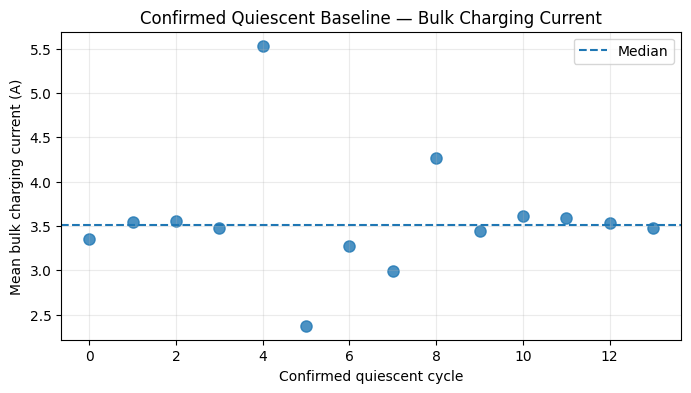

In [69]:
# ============================================================
# Confirmed quiescent baseline — bulk current
# ============================================================

fig, ax = plt.subplots(figsize=(8, 4))

ax.scatter(
    range(len(df_quiescent)),
    df_quiescent["I_bulk_mean"],
    s=65,
    alpha=0.8
)

ax.axhline(
    df_quiescent["I_bulk_mean"].median(),
    linestyle="--",
    linewidth=1.5,
    label="Median"
)

ax.set_xlabel("Confirmed quiescent cycle")
ax.set_ylabel("Mean bulk charging current (A)")
ax.set_title("Confirmed Quiescent Baseline — Bulk Charging Current")

ax.grid(alpha=0.25)
ax.legend()

plt.show()

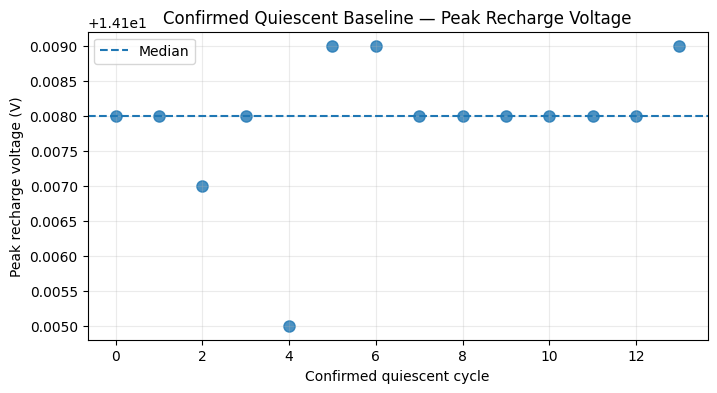

In [70]:
# ============================================================
# Confirmed quiescent baseline — peak voltage
# ============================================================

fig, ax = plt.subplots(figsize=(8, 4))

ax.scatter(
    range(len(df_quiescent)),
    df_quiescent["V_peak_charge"],
    s=65,
    alpha=0.8
)

ax.axhline(
    df_quiescent["V_peak_charge"].median(),
    linestyle="--",
    linewidth=1.5,
    label="Median"
)

ax.set_xlabel("Confirmed quiescent cycle")
ax.set_ylabel("Peak recharge voltage (V)")
ax.set_title("Confirmed Quiescent Baseline — Peak Recharge Voltage")

ax.grid(alpha=0.25)
ax.legend()

plt.show()

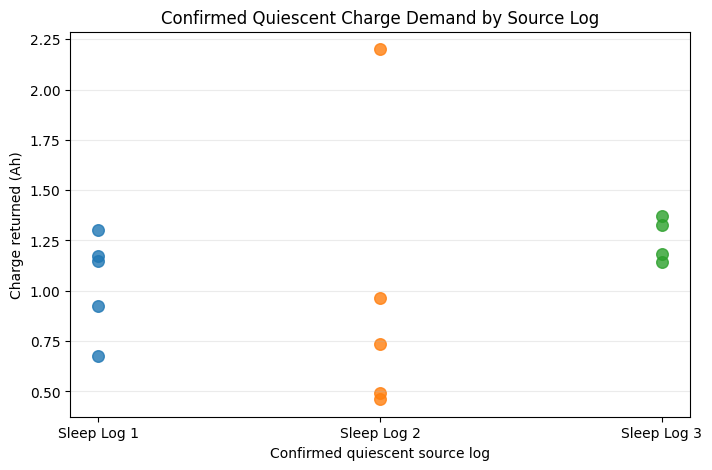

In [71]:
# ============================================================
# Charge returned by confirmed sleep source log
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5))

for source_label, subset in df_quiescent.groupby(
    "source_label"
):

    ax.scatter(
        [source_label] * len(subset),
        subset["Ah_in"],
        s=70,
        alpha=0.8,
        label=source_label
    )

ax.set_xlabel("Confirmed quiescent source log")
ax.set_ylabel("Charge returned (Ah)")
ax.set_title(
    "Confirmed Quiescent Charge Demand by Source Log"
)

ax.grid(axis="y", alpha=0.25)

plt.show()

In [72]:
model_features_v2 = [
    "Ah_in",
    "duration_s",
    "I_bulk_mean",
]

### 💡 Quiescent Baseline Feature Refinement

Analysis of the 14 confirmed quiescent cycles provides an additional
feature-selection criterion: **behavioral variance**.

`V_peak_charge` is highly observable and physically meaningful, but it
shows almost no variation within the confirmed quiescent baseline:

- Mean: 14.108 V
- Standard deviation: ~0.001 V
- Observed range: 14.105–14.109 V

Therefore, peak recharge voltage is unlikely to contribute meaningful
discrimination to the initial quiescent anomaly model.

This demonstrates an additional feature-selection principle:

> **A feature must be trustworthy, physically meaningful, and
> behaviorally informative.**

The initial quiescent behavioral representation is therefore reduced to:

- `Ah_in` — charge demand
- `duration_s` — recharge timing
- `I_bulk_mean` — recharge intensity

`V_peak_charge` remains available for engineering interpretation but is
held out of the initial anomaly model.

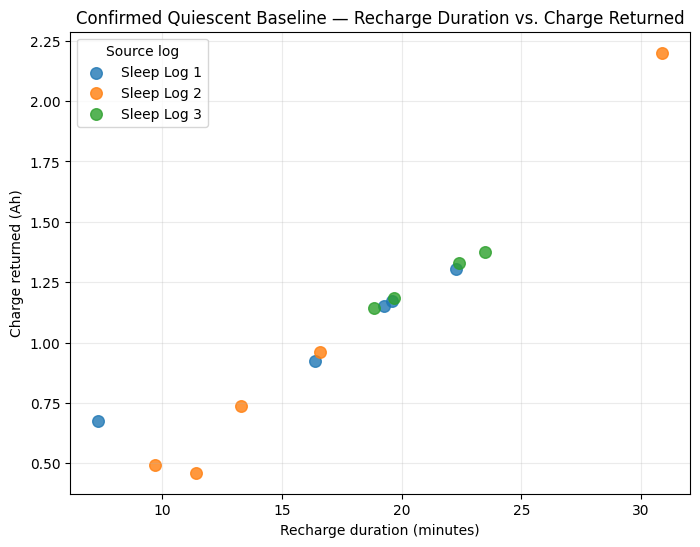

In [73]:
# ============================================================
# Confirmed quiescent baseline
# Recharge duration vs charge returned
# ============================================================

fig, ax = plt.subplots(figsize=(8, 6))

for source_label, subset in df_quiescent.groupby("source_label"):

    ax.scatter(
        subset["duration_s"] / 60,
        subset["Ah_in"],
        label=source_label,
        s=70,
        alpha=0.8
    )

ax.set_xlabel("Recharge duration (minutes)")
ax.set_ylabel("Charge returned (Ah)")
ax.set_title(
    "Confirmed Quiescent Baseline — "
    "Recharge Duration vs. Charge Returned"
)

ax.grid(alpha=0.25)
ax.legend(title="Source log")

plt.show()

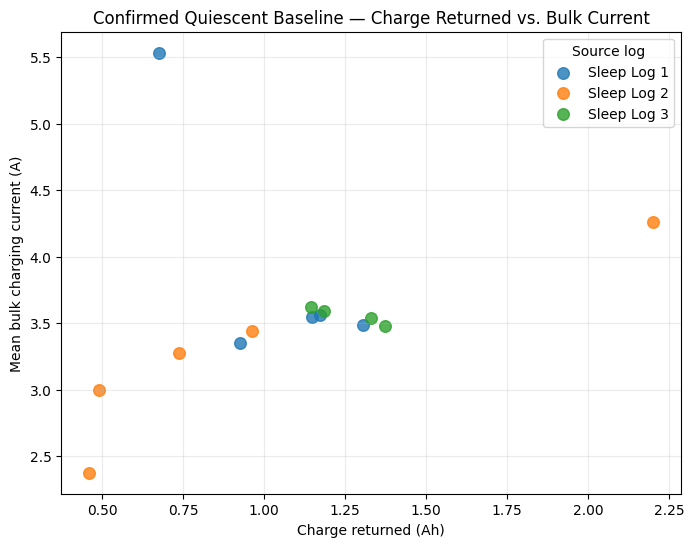

In [74]:
# ============================================================
# Confirmed quiescent baseline
# Charge returned vs bulk charging current
# ============================================================

fig, ax = plt.subplots(figsize=(8, 6))

for source_label, subset in df_quiescent.groupby("source_label"):

    ax.scatter(
        subset["Ah_in"],
        subset["I_bulk_mean"],
        label=source_label,
        s=70,
        alpha=0.8
    )

ax.set_xlabel("Charge returned (Ah)")
ax.set_ylabel("Mean bulk charging current (A)")
ax.set_title(
    "Confirmed Quiescent Baseline — "
    "Charge Returned vs. Bulk Current"
)

ax.grid(alpha=0.25)
ax.legend(title="Source log")

plt.show()

In [75]:
# ============================================================
# Confirmed quiescent cycle audit
# ============================================================

quiescent_cycle_audit = (
    df_quiescent[
        [
            "source_label",
            "cycle_id",
            "Ah_in",
            "duration_s",
            "I_bulk_mean",
        ]
    ]
    .copy()
)

quiescent_cycle_audit[
    "duration_min"
] = (
    quiescent_cycle_audit["duration_s"] / 60
)

quiescent_cycle_audit = (
    quiescent_cycle_audit[
        [
            "source_label",
            "cycle_id",
            "Ah_in",
            "duration_min",
            "I_bulk_mean",
        ]
    ]
    .sort_values(
        ["source_label", "Ah_in"]
    )
)

display(
    quiescent_cycle_audit.round(3)
)

,source_label,cycle_id,Ah_in,duration_min,I_bulk_mean
28,Sleep Log 1,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...,0.675,7.333,5.533
24,Sleep Log 1,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...,0.925,16.367,3.349
25,Sleep Log 1,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...,1.150,19.267,3.546
26,Sleep Log 1,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...,1.172,19.617,3.561
27,Sleep Log 1,12V_IBS_LIN_Normal_Dischare_12Hrs_Vehicle_slee...,1.304,22.283,3.482
29,Sleep Log 2,12V_LIN_Normal_Dischare_12Hrs_Vehicle_sleep-Ch...,0.461,11.433,2.374
31,Sleep Log 2,12V_LIN_Normal_Dischare_12Hrs_Vehicle_sleep-Ch...,0.492,9.700,2.996
30,Sleep Log 2,12V_LIN_Normal_Dischare_12Hrs_Vehicle_sleep-Ch...,0.737,13.300,3.272
33,Sleep Log 2,12V_LIN_Normal_Dischare_12Hrs_Vehicle_sleep-Ch...,0.963,16.583,3.441
32,Sleep Log 2,12V_LIN_Normal_Dischare_12Hrs_Vehicle_sleep-Ch...,2.200,30.867,4.262


### 💡 Multivariate Quiescent Behavior

Analysis of the 14 confirmed quiescent cycles shows that individual
features should not be interpreted independently.

Charge returned (`Ah_in`) and recharge duration form a coherent
relationship across all three confirmed sleep logs. The largest
observed recharge event (2.20 Ah) also has the longest recharge duration
(30.9 minutes) and elevated bulk charging current.

Although 2.20 Ah appears unusual when compared with the univariate
distribution of `Ah_in`, its accompanying features provide corroborating
evidence that the event is consistent with a larger recharge event.

This demonstrates a core Service Intelligence principle:

> **A deviation in one feature should not be treated as an anomaly when
> the multivariate vehicle behavior remains internally consistent.**

The initial quiescent behavioral baseline will therefore use a
multivariate distance measure rather than independent feature
thresholds.

The first baseline uses:

- `Ah_in`
- `duration_s`
- `I_bulk_mean`

and evaluates observations relative to the confirmed quiescent
population while accounting for correlations among these features.

### Leave-One-Out Multivariate Distance

The initial anomaly score uses **Mahalanobis distance** to measure how
far each observation lies from the confirmed quiescent behavioral
baseline.

Unlike ordinary Euclidean distance, Mahalanobis distance accounts for
correlations among the input features.

This is important because normal recharge behavior contains relationships
such as the association between charge returned and recharge duration.

The baseline uses three trusted features:

- `Ah_in`
- `duration_s`
- `I_bulk_mean`

Because only 14 confirmed quiescent observations are available, a
**leave-one-out** evaluation is used.

For each cycle:

1. Remove the cycle from the baseline dataset.
2. Estimate the feature mean and covariance from the remaining cycles.
3. Calculate the held-out cycle's Mahalanobis distance from that baseline.
4. Repeat for all confirmed quiescent cycles.

This provides an initial multivariate behavioral-deviation score without
allowing an observation to define the same baseline against which it is
evaluated.

The resulting distances are exploratory and are not interpreted as
production-calibrated anomaly thresholds.

In [76]:
# ============================================================
# Leave-one-out Mahalanobis distance
# Confirmed quiescent baseline
# ============================================================

from scipy.spatial.distance import mahalanobis

baseline_features = [
    "Ah_in",
    "duration_s",
    "I_bulk_mean",
]

X_quiescent = (
    df_quiescent[baseline_features]
    .copy()
)

mahalanobis_results = []

for idx in X_quiescent.index:

    # Held-out observation
    x_test = X_quiescent.loc[idx].values

    # Remaining observations define the baseline
    X_train = X_quiescent.drop(index=idx)

    # Baseline center
    mean_vector = X_train.mean().values

    # Covariance matrix
    covariance_matrix = np.cov(
        X_train.values,
        rowvar=False
    )

    # Pseudo-inverse is more stable than ordinary inverse
    # for a small correlated dataset
    inverse_covariance = np.linalg.pinv(
        covariance_matrix
    )

    # Mahalanobis distance
    distance = mahalanobis(
        x_test,
        mean_vector,
        inverse_covariance
    )

    mahalanobis_results.append({
        "index": idx,
        "mahalanobis_distance": distance
    })

mahalanobis_results = pd.DataFrame(
    mahalanobis_results
).set_index("index")

df_quiescent_scored = (
    df_quiescent
    .join(mahalanobis_results)
)

display(
    df_quiescent_scored[
        [
            "source_label",
            "Ah_in",
            "duration_s",
            "I_bulk_mean",
            "mahalanobis_distance",
        ]
    ]
    .sort_values(
        "mahalanobis_distance",
        ascending=False
    )
    .round(3)
)

,source_label,Ah_in,duration_s,I_bulk_mean,mahalanobis_distance
32,Sleep Log 2,2.200,"1,852.000",4.262,16.476
28,Sleep Log 1,0.675,440.000,5.533,13.356
31,Sleep Log 2,0.492,582.000,2.996,2.707
29,Sleep Log 2,0.461,686.000,2.374,2.663
37,Sleep Log 3,1.373,"1,410.000",3.479,1.898
27,Sleep Log 1,1.304,"1,337.000",3.482,1.452
36,Sleep Log 3,1.329,"1,345.000",3.536,1.326
30,Sleep Log 2,0.737,798.000,3.272,1.059
26,Sleep Log 1,1.172,"1,177.000",3.561,0.483
24,Sleep Log 1,0.925,982.000,3.349,0.466


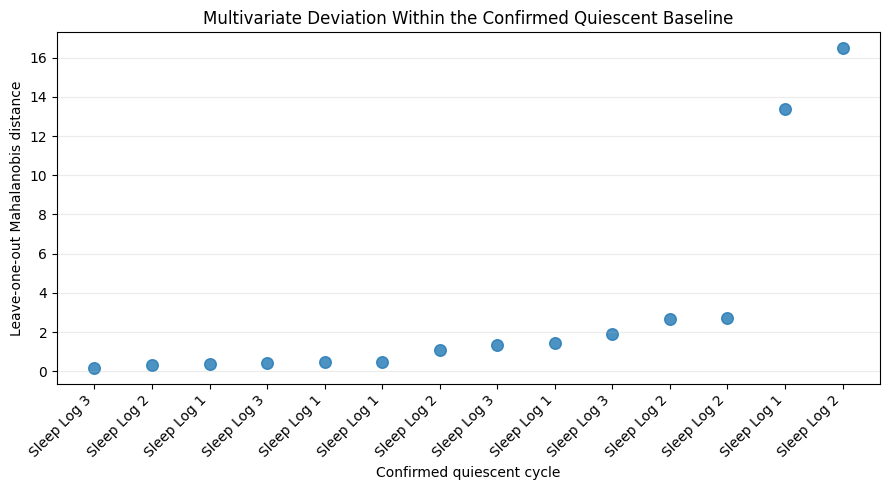

In [77]:
# ============================================================
# Mahalanobis distance
# Confirmed quiescent cycles
# ============================================================

df_quiescent_scored = (
    df_quiescent_scored
    .sort_values("mahalanobis_distance")
    .copy()
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(
    range(len(df_quiescent_scored)),
    df_quiescent_scored[
        "mahalanobis_distance"
    ],
    s=70,
    alpha=0.8
)

ax.set_xticks(
    range(len(df_quiescent_scored))
)

ax.set_xticklabels(
    df_quiescent_scored["source_label"],
    rotation=45,
    ha="right"
)

ax.set_ylabel("Leave-one-out Mahalanobis distance")
ax.set_xlabel("Confirmed quiescent cycle")

ax.set_title(
    "Multivariate Deviation Within the "
    "Confirmed Quiescent Baseline"
)

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### 💡 Initial Multivariate-Distance Findings

Leave-one-out Mahalanobis distance reveals substantial variation within
the confirmed quiescent baseline.

Most confirmed quiescent cycles occupy a relatively compact
multivariate region, while two known-normal observations receive much
larger deviation scores.

The two highest-scoring observations represent different behavioral
patterns:

- One event combines relatively low charge returned and short recharge
  duration with unusually high bulk charging current.
- One event represents the largest observed charge-return event and the
  longest recharge duration. Although these variables are physically
  coherent with one another, the event extends beyond the range of the
  remaining quiescent observations when evaluated using leave-one-out
  estimation.

This illustrates an important distinction:

> **Statistically unusual behavior is not equivalent to a confirmed
> vehicle fault.**

Both observations originate from confirmed quiescent test data and
therefore must not be relabeled as failures simply because their
multivariate distance is large.

The result also exposes a limitation of the current baseline. With only
14 confirmed observations, leave-one-out covariance estimation is
sensitive to individual observations and can produce unstable distance
estimates.

Before defining any anomaly threshold, a regularized covariance
estimator will therefore be evaluated.

In [78]:
# ============================================================
# Leave-one-out Mahalanobis distance
# Ledoit-Wolf regularized covariance
# ============================================================

from sklearn.covariance import LedoitWolf

regularized_results = []

for idx in X_quiescent.index:

    # Held-out observation
    x_test = X_quiescent.loc[idx].values

    # Remaining confirmed quiescent observations
    X_train = X_quiescent.drop(index=idx)

    # Fit regularized covariance model
    lw = LedoitWolf().fit(
        X_train.values
    )

    mean_vector = lw.location_
    precision_matrix = lw.precision_

    # Regularized Mahalanobis distance
    difference = (
        x_test - mean_vector
    )

    distance_squared = (
        difference.T
        @ precision_matrix
        @ difference
    )

    distance = np.sqrt(
        distance_squared
    )

    regularized_results.append({
        "index": idx,
        "mahalanobis_regularized": distance
    })

regularized_results = (
    pd.DataFrame(
        regularized_results
    )
    .set_index("index")
)

df_quiescent_scored = (
    df_quiescent_scored
    .join(regularized_results)
)

display(
    df_quiescent_scored[
        [
            "source_label",
            "Ah_in",
            "duration_s",
            "I_bulk_mean",
            "mahalanobis_distance",
            "mahalanobis_regularized",
        ]
    ]
    .sort_values(
        "mahalanobis_regularized",
        ascending=False
    )
    .round(3)
)

,source_label,Ah_in,duration_s,I_bulk_mean,mahalanobis_distance,mahalanobis_regularized
32,Sleep Log 2,2.200,"1,852.000",4.262,16.476,2.961
28,Sleep Log 1,0.675,440.000,5.533,13.356,2.328
31,Sleep Log 2,0.492,582.000,2.996,2.707,1.710
29,Sleep Log 2,0.461,686.000,2.374,2.663,1.300
37,Sleep Log 3,1.373,"1,410.000",3.479,1.898,1.093
30,Sleep Log 2,0.737,798.000,3.272,1.059,0.897
36,Sleep Log 3,1.329,"1,345.000",3.536,1.326,0.864
27,Sleep Log 1,1.304,"1,337.000",3.482,1.452,0.836
35,Sleep Log 3,1.185,"1,182.000",3.587,0.439,0.329
26,Sleep Log 1,1.172,"1,177.000",3.561,0.483,0.314


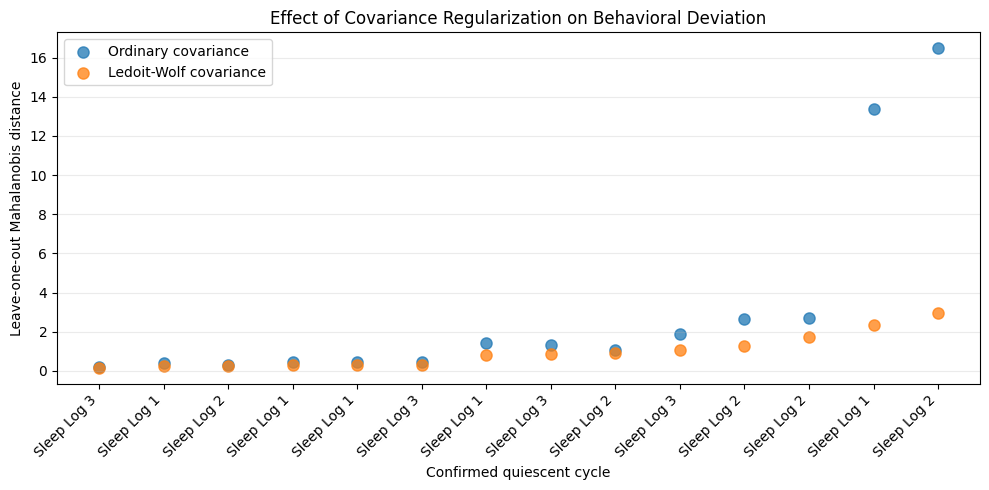

In [79]:
# ============================================================
# Ordinary vs regularized Mahalanobis distance
# ============================================================

comparison = (
    df_quiescent_scored
    .sort_values(
        "mahalanobis_regularized"
    )
    .copy()
)

x = np.arange(
    len(comparison)
)

fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.scatter(
    x,
    comparison["mahalanobis_distance"],
    label="Ordinary covariance",
    s=65,
    alpha=0.75
)

ax.scatter(
    x,
    comparison["mahalanobis_regularized"],
    label="Ledoit-Wolf covariance",
    s=65,
    alpha=0.75
)

ax.set_xticks(x)

ax.set_xticklabels(
    comparison["source_label"],
    rotation=45,
    ha="right"
)

ax.set_ylabel(
    "Leave-one-out Mahalanobis distance"
)

ax.set_xlabel(
    "Confirmed quiescent cycle"
)

ax.set_title(
    "Effect of Covariance Regularization "
    "on Behavioral Deviation"
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend()

plt.tight_layout()
plt.show()

### 💡 Regularized Behavioral Distance

Ordinary leave-one-out Mahalanobis distance proved highly sensitive to
the small confirmed-quiescent sample. Two known-normal observations
received extreme scores of approximately 13.4 and 16.5.

Replacing the ordinary sample covariance with a Ledoit-Wolf shrinkage
estimate substantially stabilizes the behavioral-distance calculation.

The same two observations remain the most unusual members of the
confirmed-normal population, but their regularized distances decrease
to approximately 2.33 and 2.96.

This is an important result.

Regularization does not eliminate the underlying behavioral differences.
Instead, it reduces overconfidence caused by estimating a multivariate
covariance structure from a small dataset.

The confirmed-normal observations now form a more gradual behavioral
continuum rather than producing two extreme numerical deviations.

For this proof of concept, Ledoit-Wolf regularized Mahalanobis distance
is therefore selected as the initial interpretable statistical baseline.

Importantly:

> **Behavioral deviation is an evidence signal, not a failure label.**

The highest behavioral-deviation scores in the current dataset occur
within confirmed-normal vehicle operation. Therefore, deviation score
alone is insufficient to trigger a service or customer action.

## 7. Anomaly Detection & Controlled Test Scenarios

Because the current dataset does not contain confirmed failure events, anomaly-detection performance cannot be validated against real vehicle failures.

Instead, the project will use **controlled synthetic perturbations of known-normal behavior** to exercise the detection pipeline.

Synthetic scenarios will be explicitly identified as test conditions and will not be presented as observed vehicle failures.

### Candidate Test Scenarios

#### Transient Anomaly
A single cycle deviates substantially from expected behavior but subsequent cycles return to normal.

Expected response:

**Detect → Log → Continue Monitoring**

#### Persistent Anomaly
Multiple consecutive parked-energy cycles deviate from the expected operating envelope.

Expected response:

**Detect → Confirm Persistence → Increase Confidence**

#### Context-Explained High Load
High energy consumption occurs while a known intentional load is active.

Expected response:

**Expected for Context → No Service Action**

#### Corroborated Quiescent Anomaly
Vehicle is expected to be quiescent but exhibits multiple unusual behaviors such as:

- Unexpected wake activity
- Increased recharge frequency
- Higher-than-expected recharge demand
- Repeated behavior over multiple parked periods

Expected response:

**Detect → Gather Evidence → Evaluate for Service Action**

### 💡 Key Distinction

> **Anomaly detection identifies behavior worth investigating. It does not determine by itself that a vehicle has failed.**

### 7.1 Context-Mismatch Experiment

The first anomaly-detection experiment uses only real, known-normal
vehicle observations.

The confirmed quiescent cycles define the expected behavioral baseline
for the Operating Mode:

**QUIESCENT**

The confirmed intentional-load cycles represent legitimate vehicle
behavior under a different Operating Mode:

**INTENTIONAL_LOAD**

The objective is not to classify intentional-load behavior as faulty.

Instead, the experiment asks:

> **If an intentional-load behavioral signature occurred while the
> vehicle was expected to be QUIESCENT, would the behavior appear
> inconsistent with the confirmed quiescent baseline?**

This provides a direct test of context-aware anomaly detection.

A behavioral pattern can therefore be:

- **Expected** under its true Operating Mode
- **Unexpected** under a different Operating Mode
- **Not inherently a vehicle fault**

The experiment uses the same three trusted behavioral features:

- `Ah_in`
- `duration_s`
- `I_bulk_mean`

and the Ledoit-Wolf regularized covariance model developed from the
confirmed quiescent baseline.

In [80]:
# ============================================================
# Fit confirmed-quiescent behavioral baseline
# ============================================================

from sklearn.covariance import LedoitWolf

baseline_features = [
    "Ah_in",
    "duration_s",
    "I_bulk_mean",
]

X_quiescent_baseline = (
    df_quiescent[baseline_features]
    .copy()
)

quiescent_model = LedoitWolf().fit(
    X_quiescent_baseline.values
)

quiescent_center = quiescent_model.location_
quiescent_precision = quiescent_model.precision_

print("Confirmed quiescent baseline fitted.")
print(f"Observations: {len(X_quiescent_baseline)}")
print(f"Features:     {len(baseline_features)}")

Confirmed quiescent baseline fitted.
Observations: 14
Features:     3


In [81]:
# ============================================================
# Behavioral-distance scoring function
# ============================================================

def score_behavioral_distance(
    dataframe,
    features,
    center,
    precision
):
    """
    Calculate regularized Mahalanobis distance
    from the confirmed behavioral baseline.
    """

    X = dataframe[features].values

    distances = []

    for x in X:

        difference = x - center

        distance_squared = (
            difference.T
            @ precision
            @ difference
        )

        distances.append(
            np.sqrt(distance_squared)
        )

    return np.array(distances)

In [82]:
# ============================================================
# Context-mismatch test populations
# ============================================================

df_quiescent_test = df_all[
    (df_all["operating_mode"] == "QUIESCENT") &
    (df_all["mode_confidence"] == "CONFIRMED")
].copy()

df_load_test = df_all[
    (df_all["operating_mode"] == "INTENTIONAL_LOAD") &
    (df_all["mode_confidence"] == "CONFIRMED")
].copy()

# Score both populations against the QUIESCENT baseline
df_quiescent_test[
    "quiescent_distance"
] = score_behavioral_distance(
    df_quiescent_test,
    baseline_features,
    quiescent_center,
    quiescent_precision
)

df_load_test[
    "quiescent_distance"
] = score_behavioral_distance(
    df_load_test,
    baseline_features,
    quiescent_center,
    quiescent_precision
)

print(
    f"Confirmed quiescent observations: "
    f"{len(df_quiescent_test)}"
)

print(
    f"Confirmed intentional-load observations: "
    f"{len(df_load_test)}"
)

Confirmed quiescent observations: 14
Confirmed intentional-load observations: 26


In [83]:
# ============================================================
# Behavioral-distance summary by true Operating Mode
# ============================================================

context_comparison = pd.DataFrame({
    "population": [
        "QUIESCENT / CONFIRMED",
        "INTENTIONAL_LOAD / CONFIRMED"
    ],

    "count": [
        len(df_quiescent_test),
        len(df_load_test)
    ],

    "median_distance": [
        df_quiescent_test[
            "quiescent_distance"
        ].median(),

        df_load_test[
            "quiescent_distance"
        ].median()
    ],

    "mean_distance": [
        df_quiescent_test[
            "quiescent_distance"
        ].mean(),

        df_load_test[
            "quiescent_distance"
        ].mean()
    ],

    "min_distance": [
        df_quiescent_test[
            "quiescent_distance"
        ].min(),

        df_load_test[
            "quiescent_distance"
        ].min()
    ],

    "max_distance": [
        df_quiescent_test[
            "quiescent_distance"
        ].max(),

        df_load_test[
            "quiescent_distance"
        ].max()
    ]
})

display(
    context_comparison.round(3)
)

,population,count,median_distance,mean_distance,min_distance,max_distance
0,QUIESCENT / CONFIRMED,14,0.795,0.850,0.166,2.332
1,INTENTIONAL_LOAD / CONFIRMED,26,2.377,2.214,0.215,4.885


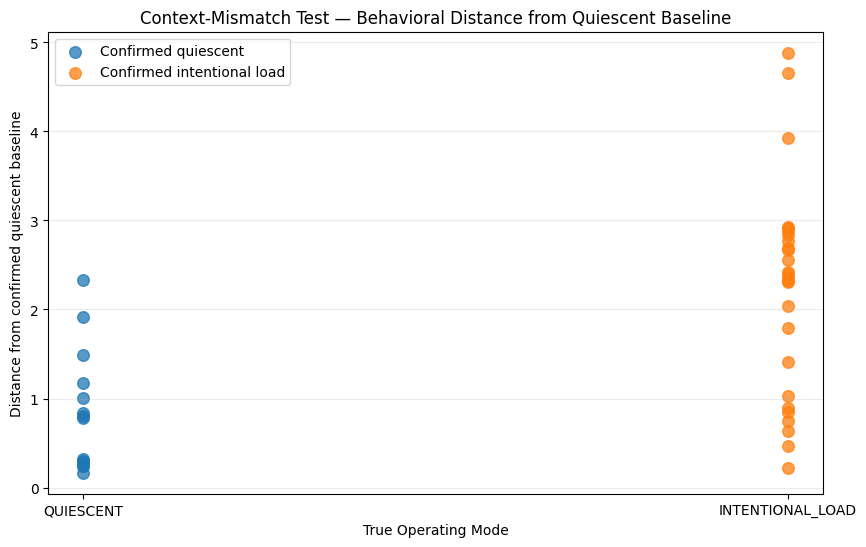

In [84]:
# ============================================================
# Context mismatch:
# Behavioral distance from confirmed quiescent baseline
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 6)
)

# Slight horizontal separation for readability
x_quiescent = np.zeros(
    len(df_quiescent_test)
)

x_load = np.ones(
    len(df_load_test)
)

ax.scatter(
    x_quiescent,
    df_quiescent_test[
        "quiescent_distance"
    ],
    s=70,
    alpha=0.75,
    label="Confirmed quiescent"
)

ax.scatter(
    x_load,
    df_load_test[
        "quiescent_distance"
    ],
    s=70,
    alpha=0.75,
    label="Confirmed intentional load"
)

ax.set_xticks([0, 1])

ax.set_xticklabels([
    "QUIESCENT",
    "INTENTIONAL_LOAD"
])

ax.set_ylabel(
    "Distance from confirmed quiescent baseline"
)

ax.set_xlabel(
    "True Operating Mode"
)

ax.set_title(
    "Context-Mismatch Test — "
    "Behavioral Distance from Quiescent Baseline"
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend()

plt.show()

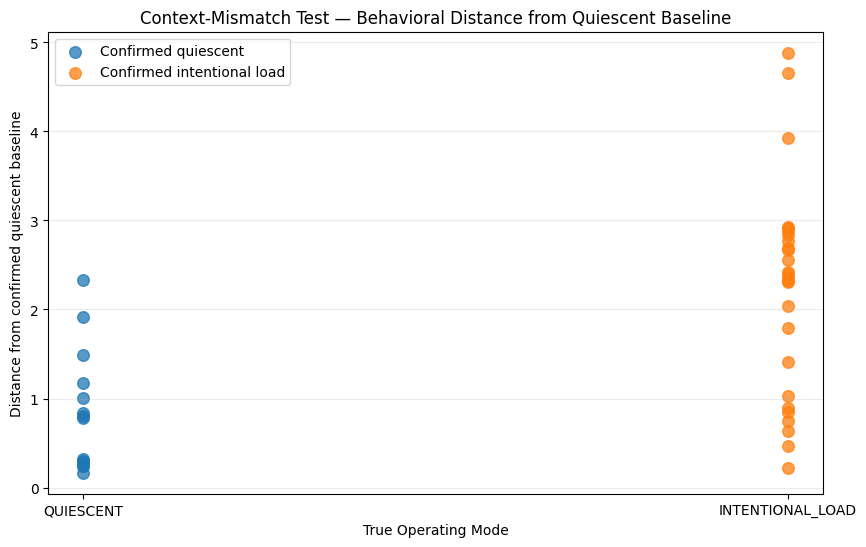

In [85]:
# ============================================================
# Context mismatch:
# Behavioral distance from confirmed quiescent baseline
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 6)
)

# Slight horizontal separation for readability
x_quiescent = np.zeros(
    len(df_quiescent_test)
)

x_load = np.ones(
    len(df_load_test)
)

ax.scatter(
    x_quiescent,
    df_quiescent_test[
        "quiescent_distance"
    ],
    s=70,
    alpha=0.75,
    label="Confirmed quiescent"
)

ax.scatter(
    x_load,
    df_load_test[
        "quiescent_distance"
    ],
    s=70,
    alpha=0.75,
    label="Confirmed intentional load"
)

ax.set_xticks([0, 1])

ax.set_xticklabels([
    "QUIESCENT",
    "INTENTIONAL_LOAD"
])

ax.set_ylabel(
    "Distance from confirmed quiescent baseline"
)

ax.set_xlabel(
    "True Operating Mode"
)

ax.set_title(
    "Context-Mismatch Test — "
    "Behavioral Distance from Quiescent Baseline"
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend()

plt.show()

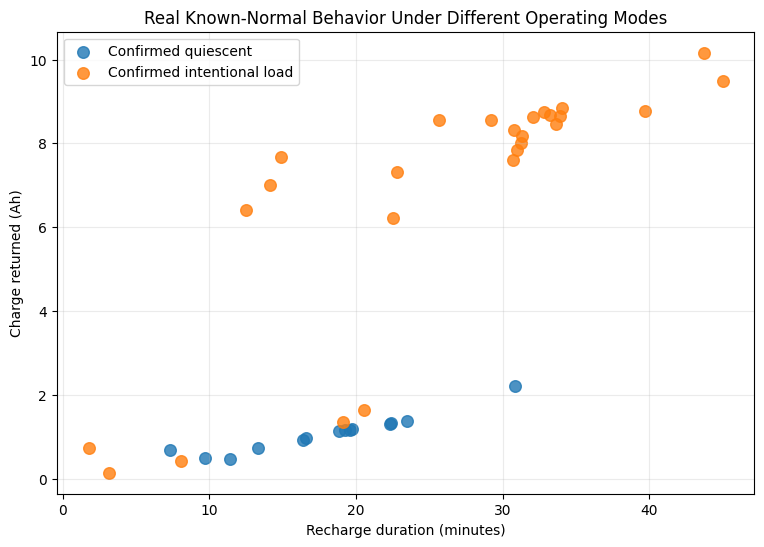

In [86]:
# ============================================================
# Physical view of context mismatch
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.scatter(
    df_quiescent_test["duration_s"] / 60,
    df_quiescent_test["Ah_in"],
    label="Confirmed quiescent",
    s=70,
    alpha=0.8
)

ax.scatter(
    df_load_test["duration_s"] / 60,
    df_load_test["Ah_in"],
    label="Confirmed intentional load",
    s=70,
    alpha=0.8
)

ax.set_xlabel(
    "Recharge duration (minutes)"
)

ax.set_ylabel(
    "Charge returned (Ah)"
)

ax.set_title(
    "Real Known-Normal Behavior Under Different Operating Modes"
)

ax.grid(alpha=0.25)
ax.legend()

plt.show()

### 💡 Context-Mismatch Findings

Real, known-normal intentional-load observations were scored against the
confirmed quiescent behavioral baseline.

The median behavioral distance for confirmed quiescent observations is
0.795, compared with 2.377 for confirmed intentional-load observations.

Thus, intentional-load behavior is generally more distant from the
quiescent behavioral baseline, demonstrating that the selected recharge
features contain useful information about whether observed behavior is
consistent with an expected quiescent state.

However, substantial overlap remains between the two populations.

Some legitimate intentional-load events produce recharge signatures
similar to confirmed quiescent behavior, while some confirmed quiescent
events receive relatively elevated behavioral-deviation scores.

This demonstrates that behavioral distance should not be interpreted as
either an Operating Mode classifier or a vehicle-failure classifier.

Importantly, every intentional-load observation in this experiment
represents known-normal vehicle behavior.

Therefore:

> **A high behavioral-deviation score means that behavior is inconsistent
> with the selected contextual baseline. It does not mean the vehicle has
> failed.**

This result supports a context-aware Service Intelligence architecture
in which behavioral deviation is one evidence signal combined with
Operating Mode, persistence, signal quality, and corroborating vehicle
behavior before an action is taken.

### 7.2 From Behavioral Detection to Service Decision

Behavioral deviation alone should not create a customer or service
notification.

A production vehicle may occasionally exhibit unusual but legitimate
behavior. Escalating every deviation would create the equivalent of a
persistent check-engine light: technically sensitive but operationally
unhelpful.

The initial Service Intelligence decision layer therefore separates:

**Detection → Persistence → Context → Evidence → Action**

Three controlled scenarios are evaluated using real measured vehicle
cycles:

1. **Transient deviation** — one unusual quiescent event followed by
   normal behavior.
2. **Persistent deviation** — repeated behavior inconsistent with the
   expected quiescent baseline.
3. **Context-explained deviation** — behavior is highly inconsistent
   with the quiescent baseline but occurs during a confirmed
   intentional-load Operating Mode.

These scenarios are not simulated vehicle failures.

They are controlled decision experiments designed to demonstrate how
the same behavioral-deviation evidence should produce different system
responses depending on persistence and Operating Mode.

In [87]:
# ============================================================
# Exploratory behavioral-deviation reference
# ============================================================

quiescent_reference_max = (
    df_quiescent_test[
        "quiescent_distance"
    ].max()
)

print(
    "Maximum behavioral distance observed "
    "in confirmed quiescent baseline:"
)

print(
    f"{quiescent_reference_max:.3f}"
)

Maximum behavioral distance observed in confirmed quiescent baseline:
2.332


In [88]:
# Exploratory only — NOT a validated production threshold

def is_elevated(distance):
    return distance > quiescent_reference_max

In [89]:
# ============================================================
# Select real measured cycles for controlled scenarios
# ============================================================

# Typical quiescent observation:
# closest to median quiescent behavioral distance
quiescent_median_distance = (
    df_quiescent_test[
        "quiescent_distance"
    ].median()
)

typical_quiescent_idx = (
    (
        df_quiescent_test[
            "quiescent_distance"
        ]
        - quiescent_median_distance
    )
    .abs()
    .idxmin()
)

typical_quiescent = (
    df_quiescent_test.loc[
        typical_quiescent_idx
    ]
)

# Most quiescent-inconsistent real intentional-load observation
high_deviation_load_idx = (
    df_load_test[
        "quiescent_distance"
    ].idxmax()
)

high_deviation_load = (
    df_load_test.loc[
        high_deviation_load_idx
    ]
)

print(
    "Typical quiescent distance:",
    round(
        typical_quiescent[
            "quiescent_distance"
        ],
        3
    )
)

print(
    "High-deviation intentional-load distance:",
    round(
        high_deviation_load[
            "quiescent_distance"
        ],
        3
    )
)

Typical quiescent distance: 0.783
High-deviation intentional-load distance: 4.885


In [90]:
# ============================================================
# Scenario A — transient deviation
# ============================================================

scenario_transient = pd.DataFrame({
    "cycle": [1, 2, 3, 4],

    "behavior_source": [
        "Measured quiescent",
        "Measured high-deviation cycle",
        "Measured quiescent",
        "Measured quiescent",
    ],

    "expected_mode": [
        "QUIESCENT",
        "QUIESCENT",
        "QUIESCENT",
        "QUIESCENT",
    ],

    "distance": [
        typical_quiescent["quiescent_distance"],
        high_deviation_load["quiescent_distance"],
        typical_quiescent["quiescent_distance"],
        typical_quiescent["quiescent_distance"],
    ],
})

scenario_transient["elevated"] = (
    scenario_transient["distance"]
    .apply(is_elevated)
)

display(
    scenario_transient.round(3)
)

,cycle,behavior_source,expected_mode,distance,elevated
0,1,Measured quiescent,QUIESCENT,0.783,False
1,2,Measured high-deviation cycle,QUIESCENT,4.885,True
2,3,Measured quiescent,QUIESCENT,0.783,False
3,4,Measured quiescent,QUIESCENT,0.783,False


In [91]:
# ============================================================
# Scenario B — persistent deviation
# ============================================================

scenario_persistent = pd.DataFrame({
    "cycle": [1, 2, 3],

    "behavior_source": [
        "Measured high-deviation cycle",
        "Measured high-deviation cycle",
        "Measured high-deviation cycle",
    ],

    "expected_mode": [
        "QUIESCENT",
        "QUIESCENT",
        "QUIESCENT",
    ],

    "distance": [
        high_deviation_load["quiescent_distance"],
        high_deviation_load["quiescent_distance"],
        high_deviation_load["quiescent_distance"],
    ],
})

scenario_persistent["elevated"] = (
    scenario_persistent["distance"]
    .apply(is_elevated)
)

display(
    scenario_persistent.round(3)
)

,cycle,behavior_source,expected_mode,distance,elevated
0,1,Measured high-deviation cycle,QUIESCENT,4.885,True
1,2,Measured high-deviation cycle,QUIESCENT,4.885,True
2,3,Measured high-deviation cycle,QUIESCENT,4.885,True


In [92]:
# ============================================================
# Scenario C — context-explained deviation
# ============================================================

scenario_context = pd.DataFrame({
    "cycle": [1],

    "behavior_source": [
        "Measured intentional-load cycle"
    ],

    "expected_mode": [
        "INTENTIONAL_LOAD"
    ],

    "distance_from_quiescent": [
        high_deviation_load[
            "quiescent_distance"
        ]
    ],

    "quiescent_reference_exceeded": [
        is_elevated(
            high_deviation_load[
                "quiescent_distance"
            ]
        )
    ]
})

display(
    scenario_context.round(3)
)

,cycle,behavior_source,expected_mode,distance_from_quiescent,quiescent_reference_exceeded
0,1,Measured intentional-load cycle,INTENTIONAL_LOAD,4.885,True


In [93]:
# ============================================================
# Prototype Service Intelligence decision logic
# ============================================================

def service_intelligence_decision(
    expected_mode,
    elevated_sequence
):
    """
    Prototype decision logic for the case study.

    This is intentionally simple and is not
    production-calibrated logic.
    """

    elevated_count = sum(
        elevated_sequence
    )

    total_cycles = len(
        elevated_sequence
    )

    # Context explained
    if expected_mode != "QUIESCENT":
        return {
            "decision": "EXPECTED_FOR_CONTEXT",
            "customer_notification": "NO",
            "action": "No quiescent service action"
        }

    # No elevated behavior
    if elevated_count == 0:
        return {
            "decision": "NORMAL",
            "customer_notification": "NO",
            "action": "No action"
        }

    # One transient event
    if elevated_count == 1:
        return {
            "decision": "MONITOR",
            "customer_notification": "NO",
            "action": "Log silently and monitor subsequent cycles"
        }

    # Repeated elevated behavior
    if (
        elevated_count >= 2
        and total_cycles >= 2
    ):
        return {
            "decision": "GATHER_EVIDENCE",
            "customer_notification": "NO",
            "action": (
                "Increase diagnostic observation "
                "and collect corroborating telemetry"
            )
        }

In [94]:
# ============================================================
# Evaluate controlled decision scenarios
# ============================================================

decision_transient = (
    service_intelligence_decision(
        expected_mode="QUIESCENT",
        elevated_sequence=
            scenario_transient["elevated"].tolist()
    )
)

decision_persistent = (
    service_intelligence_decision(
        expected_mode="QUIESCENT",
        elevated_sequence=
            scenario_persistent["elevated"].tolist()
    )
)

decision_context = (
    service_intelligence_decision(
        expected_mode="INTENTIONAL_LOAD",
        elevated_sequence=[
            scenario_context[
                "quiescent_reference_exceeded"
            ].iloc[0]
        ]
    )
)

decision_summary = pd.DataFrame([
    {
        "scenario": "A — Transient deviation",
        **decision_transient
    },
    {
        "scenario": "B — Persistent deviation",
        **decision_persistent
    },
    {
        "scenario": "C — Context explained",
        **decision_context
    },
])

display(
    decision_summary
)

,scenario,decision,customer_notification,action
0,A — Transient deviation,MONITOR,NO,Log silently and monitor subsequent cycles
1,B — Persistent deviation,GATHER_EVIDENCE,NO,Increase diagnostic observation and collect co...
2,C — Context explained,EXPECTED_FOR_CONTEXT,NO,No quiescent service action


### 💡 From Anomaly Detection to Decision Quality

The controlled decision scenarios demonstrate that identical or similar
behavioral-deviation evidence can appropriately produce different
responses depending on context and persistence.

A single elevated event during expected quiescent operation does not
trigger a customer notification. The event is retained and subsequent
behavior is monitored.

Repeated elevated behavior increases confidence that the deviation is
persistent, but still does not establish a root cause. The appropriate
next action is to gather additional diagnostic evidence.

The same high-deviation behavioral signature occurring during a known
intentional-load Operating Mode is expected for context and does not
generate a quiescent service action.

This demonstrates the distinction between **detection sensitivity** and
**action sensitivity**:

> **The system can be sensitive internally while remaining selective
> about when it interrupts a customer or technician.**

The prototype therefore implements the sequence:

**Detect → Contextualize → Observe Persistence → Gather Evidence → Act**

rather than:

**Detect → Notify**

This false-positive suppression strategy is a core requirement of the
proposed Vehicle Service Intelligence architecture.

### 7.3 Isolation Forest Comparison

The regularized Mahalanobis baseline provides an interpretable,
correlation-aware measure of behavioral deviation from confirmed
quiescent operation.

A second anomaly-detection method is now evaluated to determine whether
a nonlinear unsupervised model provides additional useful information.

**Isolation Forest** is selected because it can identify observations
that are easier to isolate from the normal training population without
requiring the data to follow a multivariate normal distribution.

The model is trained only on the same three trusted features used by
the statistical baseline:

- `Ah_in`
- `duration_s`
- `I_bulk_mean`

and only on the 14 confirmed quiescent cycles.

Operating Mode is not supplied to the model.

The objective is not to determine which algorithm produces the largest
anomaly score.

The objective is to compare whether Isolation Forest provides useful
behavioral discrimination beyond the simpler and more interpretable
regularized Mahalanobis baseline.

Because the confirmed quiescent training population contains only 14
observations, Isolation Forest results are treated as exploratory.

In [95]:
# ============================================================
# Prepare trusted features for Isolation Forest
# ============================================================

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

if_features = [
    "Ah_in",
    "duration_s",
    "I_bulk_mean",
]

if_scaler = StandardScaler()

X_if_quiescent = if_scaler.fit_transform(
    df_quiescent_test[if_features]
)

X_if_load = if_scaler.transform(
    df_load_test[if_features]
)

print(
    "Isolation Forest training observations:",
    len(X_if_quiescent)
)

print(
    "Features:",
    len(if_features)
)

Isolation Forest training observations: 14
Features: 3


In [96]:
contamination="auto"

In [97]:
# ============================================================
# Fit Isolation Forest
# Confirmed quiescent baseline only
# ============================================================

isolation_forest = IsolationForest(
    n_estimators=500,
    contamination="auto",
    random_state=42
)

isolation_forest.fit(
    X_if_quiescent
)

print(
    "Isolation Forest fitted "
    "to confirmed quiescent baseline."
)

Isolation Forest fitted to confirmed quiescent baseline.


In [98]:
# ============================================================
# Isolation Forest behavioral-deviation scores
# Higher value = greater deviation
# ============================================================

df_quiescent_test[
    "if_deviation_score"
] = -isolation_forest.score_samples(
    X_if_quiescent
)

df_load_test[
    "if_deviation_score"
] = -isolation_forest.score_samples(
    X_if_load
)

print("Isolation Forest scores calculated.")

Isolation Forest scores calculated.


In [99]:
# ============================================================
# Isolation Forest score summary
# ============================================================

if_comparison = pd.DataFrame({
    "population": [
        "QUIESCENT / CONFIRMED",
        "INTENTIONAL_LOAD / CONFIRMED"
    ],

    "count": [
        len(df_quiescent_test),
        len(df_load_test)
    ],

    "median_IF_score": [
        df_quiescent_test[
            "if_deviation_score"
        ].median(),

        df_load_test[
            "if_deviation_score"
        ].median()
    ],

    "mean_IF_score": [
        df_quiescent_test[
            "if_deviation_score"
        ].mean(),

        df_load_test[
            "if_deviation_score"
        ].mean()
    ],

    "min_IF_score": [
        df_quiescent_test[
            "if_deviation_score"
        ].min(),

        df_load_test[
            "if_deviation_score"
        ].min()
    ],

    "max_IF_score": [
        df_quiescent_test[
            "if_deviation_score"
        ].max(),

        df_load_test[
            "if_deviation_score"
        ].max()
    ],
})

display(
    if_comparison.round(3)
)

,population,count,median_IF_score,mean_IF_score,min_IF_score,max_IF_score
0,QUIESCENT / CONFIRMED,14,0.419,0.468,0.369,0.705
1,INTENTIONAL_LOAD / CONFIRMED,26,0.744,0.693,0.471,0.745


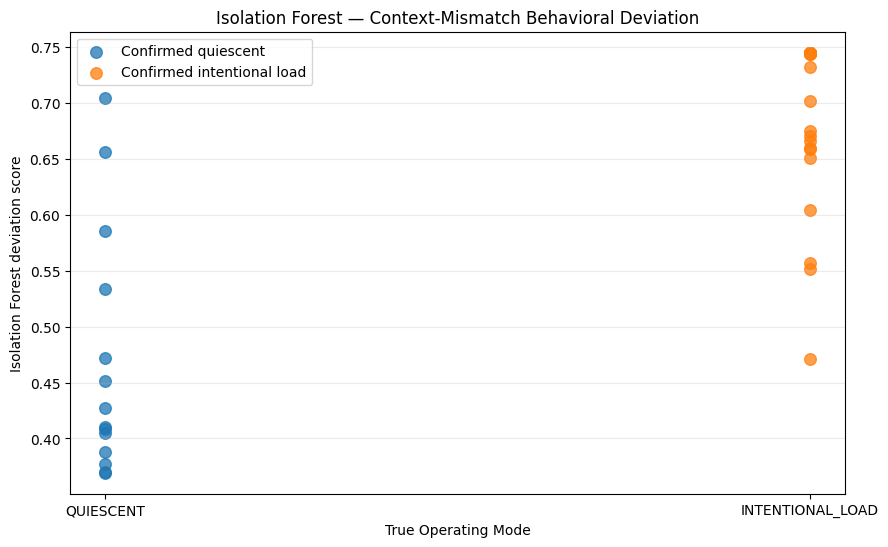

In [100]:
# ============================================================
# Isolation Forest context-mismatch comparison
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.scatter(
    np.zeros(len(df_quiescent_test)),
    df_quiescent_test["if_deviation_score"],
    label="Confirmed quiescent",
    s=70,
    alpha=0.75
)

ax.scatter(
    np.ones(len(df_load_test)),
    df_load_test["if_deviation_score"],
    label="Confirmed intentional load",
    s=70,
    alpha=0.75
)

ax.set_xticks([0, 1])

ax.set_xticklabels([
    "QUIESCENT",
    "INTENTIONAL_LOAD"
])

ax.set_ylabel(
    "Isolation Forest deviation score"
)

ax.set_xlabel(
    "True Operating Mode"
)

ax.set_title(
    "Isolation Forest — "
    "Context-Mismatch Behavioral Deviation"
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend()

plt.show()

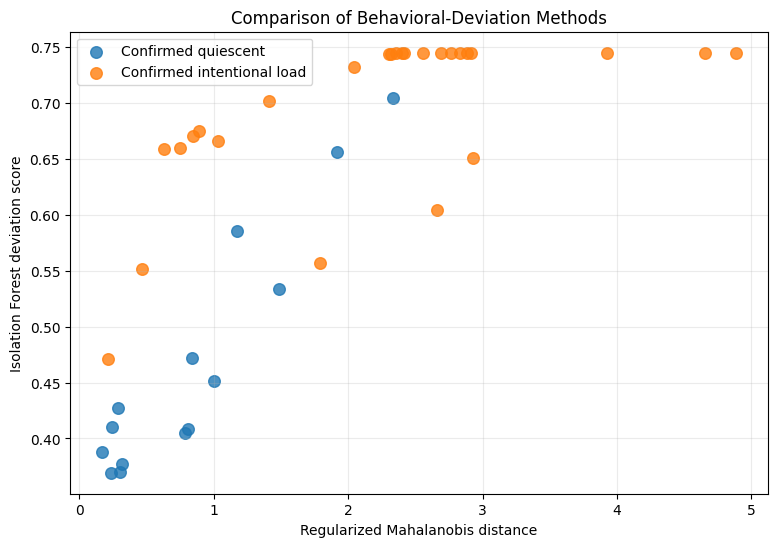

In [101]:
# ============================================================
# Compare Mahalanobis and Isolation Forest
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.scatter(
    df_quiescent_test["quiescent_distance"],
    df_quiescent_test["if_deviation_score"],
    label="Confirmed quiescent",
    s=70,
    alpha=0.8
)

ax.scatter(
    df_load_test["quiescent_distance"],
    df_load_test["if_deviation_score"],
    label="Confirmed intentional load",
    s=70,
    alpha=0.8
)

ax.set_xlabel(
    "Regularized Mahalanobis distance"
)

ax.set_ylabel(
    "Isolation Forest deviation score"
)

ax.set_title(
    "Comparison of Behavioral-Deviation Methods"
)

ax.grid(alpha=0.25)
ax.legend()

plt.show()

In [102]:
# ============================================================
# Correlation between anomaly scoring methods
# ============================================================

combined_scores = pd.concat([
    df_quiescent_test[
        [
            "quiescent_distance",
            "if_deviation_score"
        ]
    ],

    df_load_test[
        [
            "quiescent_distance",
            "if_deviation_score"
        ]
    ]
])

score_correlation = (
    combined_scores[
        "quiescent_distance"
    ]
    .corr(
        combined_scores[
            "if_deviation_score"
        ]
    )
)

print(
    "Correlation between Mahalanobis "
    "and Isolation Forest scores:"
)

print(
    f"{score_correlation:.3f}"
)

Correlation between Mahalanobis and Isolation Forest scores:
0.764


### 💡 Model Comparison

Isolation Forest and regularized Mahalanobis distance show substantial
agreement in their assessment of behavioral deviation from the confirmed
quiescent baseline.

Across the confirmed quiescent and intentional-load observations, the
two continuous deviation scores have a Pearson correlation of:

**r = 0.764**

Both methods generally assign larger deviation scores to
intentional-load behavior when it is evaluated against the quiescent
baseline.

However, the methods are not identical.

Isolation Forest tends to saturate for observations that are clearly
separated from the small quiescent training population, while
Mahalanobis distance continues to represent increasing multivariate
distance from the baseline.

Given the current dataset, regularized Mahalanobis distance is retained
as the primary behavioral-deviation method because:

- the confirmed baseline contains only 14 observations,
- the method explicitly accounts for relationships among trusted
  physical features,
- the resulting distance is comparatively interpretable,
- and Isolation Forest does not yet demonstrate sufficient incremental
  value to justify making the more complex model primary.

Isolation Forest is retained as a comparison model and as a candidate
for future evaluation with larger and more diverse fleet datasets.

### Modeling Principle

> **Model complexity should be earned by demonstrated improvement in
> decision quality, not added simply because a more sophisticated
> algorithm is available.**

## 8. Confidence Engine & False-Positive Suppression

A major design objective of Vehicle Service Intelligence is avoiding the
equivalent of a permanently illuminated check-engine light.

A sensitive anomaly detector may be useful internally, but customer and
technician attention should have a significantly higher threshold.

Therefore:

> **Anomaly ≠ Notification**

Section 7 demonstrated this directly. Known-normal vehicle behavior can
produce elevated behavioral-deviation scores, and behavior that is normal
under one Operating Mode may appear anomalous when evaluated against a
different contextual baseline.

The Confidence Engine therefore sits between **anomaly detection** and
**Service Intelligence**.

Its purpose is to determine whether detected behavioral deviation is
sufficiently trustworthy, persistent, corroborated, and actionable to
justify escalation.

### Confidence Factors

Potential confidence inputs include:

- Magnitude of behavioral deviation
- Signal quality / observability
- Operating Mode and mode confidence
- Persistence across multiple cycles
- Recurrence frequency
- Corroborating vehicle signals
- Vehicle-specific historical baseline
- Comparable-vehicle / fleet baseline
- Battery State of Health
- Known software or operating changes

### Behavioral Confidence vs. Diagnostic Confidence

These are intentionally treated as different concepts.

The system may have:

**High behavioral confidence**

> The observed vehicle behavior is inconsistent with the expected baseline.

while simultaneously having:

**Low diagnostic confidence**

> The available evidence is insufficient to identify the responsible
> subsystem or root cause.

In this condition, the appropriate response is additional evidence
collection rather than a customer notification or premature diagnosis.

### Decision Levels

Potential system responses include:

1. **Expected** — behavior is consistent with context; no action
2. **Observe** — retain the deviation silently
3. **Monitor** — evaluate persistence across subsequent cycles
4. **Gather Evidence** — request targeted diagnostic telemetry
5. **Remote / Engineering Action** — investigate software or fleet-level behavior
6. **Service Action** — create an evidence-backed service event

Safety-critical conditions are outside the scope of this experimental
behavioral model and should follow separately validated vehicle safety
mechanisms.

### 💡 Design Principle

> **The system should have a low threshold for noticing something and a
> much higher threshold for interrupting a customer or technician.**

In [108]:
# ============================================================
# Confidence Engine — evidence-state representation
# ============================================================

confidence_states = pd.DataFrame([
    {
        "evidence_dimension": "Signal Confidence",
        "current_state": "HIGH",
        "basis": (
            "Recharge-event signals are observable during "
            "the measured recharge interval."
        )
    },
    {
        "evidence_dimension": "Context Confidence",
        "current_state": "HIGH",
        "basis": (
            "Expected QUIESCENT Operating Mode is assumed "
            "confirmed for the controlled decision scenario."
        )
    },
    {
        "evidence_dimension": "Behavioral Deviation",
        "current_state": "HIGH",
        "basis": (
            "Measured behavior exceeds the confirmed "
            "quiescent behavioral reference."
        )
    },
    {
        "evidence_dimension": "Persistence",
        "current_state": "HIGH",
        "basis": (
            "Controlled scenario assumes repeated elevated "
            "behavior across three consecutive cycles."
        )
    },
    {
        "evidence_dimension": "Corroboration",
        "current_state": "LIMITED",
        "basis": (
            "Recharge behavior is available, but targeted "
            "wake/ECU evidence is not yet available."
        )
    },
    {
        "evidence_dimension": "Root-Cause Confidence",
        "current_state": "LOW",
        "basis": (
            "Behavioral evidence does not identify the "
            "subsystem responsible for the deviation."
        )
    }
])

display(confidence_states)

,evidence_dimension,current_state,basis
0,Signal Confidence,HIGH,Recharge-event signals are observable during t...
1,Context Confidence,HIGH,Expected QUIESCENT Operating Mode is assumed c...
2,Behavioral Deviation,HIGH,Measured behavior exceeds the confirmed quiesc...
3,Persistence,HIGH,Controlled scenario assumes repeated elevated ...
4,Corroboration,LIMITED,"Recharge behavior is available, but targeted w..."
5,Root-Cause Confidence,LOW,Behavioral evidence does not identify the subs...


In [109]:
# ============================================================
# Confidence Engine — escalation states
# ============================================================

escalation_states = pd.DataFrame([
    {
        "level": 0,
        "state": "EXPECTED",
        "system_response": "No action",
        "customer_notification": "NO"
    },
    {
        "level": 1,
        "state": "OBSERVE",
        "system_response": "Log behavioral deviation silently",
        "customer_notification": "NO"
    },
    {
        "level": 2,
        "state": "MONITOR",
        "system_response": "Evaluate persistence across future cycles",
        "customer_notification": "NO"
    },
    {
        "level": 3,
        "state": "GATHER_EVIDENCE",
        "system_response": "Capture targeted diagnostic telemetry",
        "customer_notification": "NO"
    },
    {
        "level": 4,
        "state": "ACTIONABLE",
        "system_response": "Create evidence-backed service action",
        "customer_notification": "CONDITIONAL"
    }
])

display(escalation_states)

,level,state,system_response,customer_notification
0,0,EXPECTED,No action,NO
1,1,OBSERVE,Log behavioral deviation silently,NO
2,2,MONITOR,Evaluate persistence across future cycles,NO
3,3,GATHER_EVIDENCE,Capture targeted diagnostic telemetry,NO
4,4,ACTIONABLE,Create evidence-backed service action,CONDITIONAL


### 💡 Confidence Engine Result

For the controlled persistent-deviation scenario, the Confidence Engine
has sufficient evidence to conclude that the observed behavior deserves
additional investigation:

- Signal confidence: **HIGH**
- Context confidence: **HIGH**
- Behavioral deviation: **HIGH**
- Persistence: **HIGH**

However:

- Corroboration: **LIMITED**
- Root-cause confidence: **LOW**

The event therefore advances to:

**GATHER EVIDENCE**

rather than directly to a customer notification or service action.

This demonstrates the intended false-positive suppression strategy:

> **High confidence that something is unusual does not imply high
> confidence about what is wrong.**

The next system action should reduce that uncertainty before escalating
the event further.

## 9. From Vehicle Intelligence to Service Intelligence

The final objective is not simply to produce an anomaly score.

The objective is to convert vehicle behavior into an **evidence-backed next-best action**.

A Service Intelligence event may combine:

- Vehicle operating context
- Behavioral anomaly assessment
- Battery State of Health
- Wake/sleep behavior
- Signal quality
- Event persistence
- Historical vehicle behavior
- Fleet/cohort behavior
- Available diagnostic evidence

### Example Decision Logic

A future system may distinguish between:

**Battery degradation**
→ investigate or replace the battery when supporting evidence is sufficient

**Unexpected parked-energy / wake behavior**
→ investigate the source of the unexpected load or wake event before replacing the battery

**Insufficient evidence**
→ collect additional targeted telemetry before creating a service event

**Fleet-wide behavior**
→ route toward engineering/software investigation rather than individual vehicle service

### Customer Experience Principle

The customer should only be notified when the system has something useful to communicate or an appropriate action to recommend.

The customer does not need an anomaly score.

The service organization needs:

**What happened → Why it matters → Supporting evidence → Recommended next action**

### 9.1 Service Intelligence Event

The behavioral model does not directly generate a customer warning,
diagnosis, or repair recommendation.

Instead, Vehicle Intelligence produces a structured **Service
Intelligence Event** containing the available evidence about the
observed behavior.

The event separates:

- **Observed facts** — measurements derived from vehicle telemetry
- **Context** — what the vehicle was expected to be doing
- **Behavioral assessment** — deviation from the expected baseline
- **Persistence** — whether the behavior has repeated
- **Evidence quality** — whether the underlying telemetry is trustworthy
- **Diagnostic confidence** — whether sufficient evidence exists to
  identify a likely cause
- **Recommended next action** — what the system should do next

This separation is important because:

> **Detection confidence is not the same as diagnostic confidence.**

The system may be highly confident that vehicle behavior is unusual
while still having insufficient evidence to determine why it occurred.

In that case, the appropriate response is additional evidence
collection rather than a customer notification or premature diagnosis.

In [103]:
# ============================================================
# Select real measured behavior for Service Intelligence demo
# ============================================================

service_demo_cycle = (
    df_load_test
    .loc[
        df_load_test[
            "quiescent_distance"
        ].idxmax()
    ]
)

service_demo_measurement = {
    "Ah_in": service_demo_cycle["Ah_in"],
    "duration_s": service_demo_cycle["duration_s"],
    "I_bulk_mean": service_demo_cycle["I_bulk_mean"],
    "behavioral_distance":
        service_demo_cycle["quiescent_distance"],
    "isolation_forest_score":
        service_demo_cycle["if_deviation_score"],
}

display(
    pd.DataFrame(
        [service_demo_measurement]
    ).round(3)
)

,Ah_in,duration_s,I_bulk_mean,behavioral_distance,isolation_forest_score
0,9.489,"2,700.000",12.639,4.885,0.745


In [104]:
# ============================================================
# Compare event with confirmed quiescent baseline
# ============================================================

def robust_feature_context(
    value,
    baseline_series
):
    median = baseline_series.median()
    q1 = baseline_series.quantile(0.25)
    q3 = baseline_series.quantile(0.75)
    iqr = q3 - q1

    if iqr == 0:
        robust_deviation = np.nan
    else:
        robust_deviation = (
            value - median
        ) / iqr

    return {
        "value": value,
        "baseline_median": median,
        "baseline_q1": q1,
        "baseline_q3": q3,
        "robust_deviation": robust_deviation,
    }


event_feature_evidence = {
    "Ah_in": robust_feature_context(
        service_demo_cycle["Ah_in"],
        df_quiescent["Ah_in"]
    ),

    "duration_s": robust_feature_context(
        service_demo_cycle["duration_s"],
        df_quiescent["duration_s"]
    ),

    "I_bulk_mean": robust_feature_context(
        service_demo_cycle["I_bulk_mean"],
        df_quiescent["I_bulk_mean"]
    ),
}

evidence_table = pd.DataFrame(
    event_feature_evidence
).T

display(
    evidence_table.round(3)
)

,value,baseline_median,baseline_q1,baseline_q3,robust_deviation
Ah_in,9.489,1.147,0.784,1.274,16.997
duration_s,"2,700.000","1,144.000",844.000,"1,298.250",3.425
I_bulk_mean,12.639,3.509,3.372,3.580,43.742


In [105]:
# ============================================================
# Vehicle Service Intelligence Event
# ============================================================

service_event = {

    # ----------------------------------------
    # Event identity
    # ----------------------------------------
    "event_type":
        "PARKED_ENERGY_BEHAVIOR",

    # ----------------------------------------
    # Vehicle context
    # SIMULATED for this decision experiment
    # ----------------------------------------
    "expected_operating_mode":
        "QUIESCENT",

    "mode_confidence":
        "CONFIRMED",

    # ----------------------------------------
    # Measured vehicle behavior
    # ----------------------------------------
    "measured_behavior": {
        "Ah_in":
            float(service_demo_cycle["Ah_in"]),

        "recharge_duration_s":
            float(service_demo_cycle["duration_s"]),

        "I_bulk_mean":
            float(service_demo_cycle["I_bulk_mean"]),
    },

    # ----------------------------------------
    # Derived behavioral evidence
    # ----------------------------------------
    "behavioral_assessment": {
        "quiescent_distance":
            float(
                service_demo_cycle[
                    "quiescent_distance"
                ]
            ),

        "isolation_forest_score":
            float(
                service_demo_cycle[
                    "if_deviation_score"
                ]
            ),

        "baseline":
            "CONFIRMED_QUIESCENT",
    },

    # ----------------------------------------
    # Persistence
    # SIMULATED for decision experiment
    # ----------------------------------------
    "persistence": {
        "consecutive_elevated_cycles": 3,
        "status": "PERSISTENT",
    },

    # ----------------------------------------
    # Signal / data quality
    # ----------------------------------------
    "evidence_quality": {
        "recharge_signals":
            "HIGH",

        "sleep_current_observability":
            "LIMITED",

        "overall":
            "SUFFICIENT_FOR_BEHAVIORAL_ASSESSMENT",
    },

    # ----------------------------------------
    # Diagnostic interpretation
    # ----------------------------------------
    "diagnostic_assessment": {
        "behavioral_deviation":
            "HIGH",

        "root_cause":
            "UNKNOWN",

        "root_cause_confidence":
            "LOW",
    },
}

In [106]:
# ============================================================
# Service Intelligence next-best-action logic
# ============================================================

def determine_next_best_action(event):

    expected_mode = event[
        "expected_operating_mode"
    ]

    persistence = event[
        "persistence"
    ]["status"]

    root_cause_confidence = event[
        "diagnostic_assessment"
    ]["root_cause_confidence"]

    behavioral_deviation = event[
        "diagnostic_assessment"
    ]["behavioral_deviation"]

    # Behavior explained by known context
    if expected_mode != "QUIESCENT":

        return {
            "decision":
                "EXPECTED_FOR_CONTEXT",

            "customer_notification":
                "NO",

            "next_action":
                "NO_SERVICE_ACTION"
        }

    # Persistent deviation but cause unknown
    if (
        behavioral_deviation == "HIGH"
        and persistence == "PERSISTENT"
        and root_cause_confidence == "LOW"
    ):

        return {
            "decision":
                "GATHER_EVIDENCE",

            "customer_notification":
                "NO",

            "next_action":
                "CAPTURE_TARGETED_WAKE_TELEMETRY"
        }

    return {
        "decision":
            "MONITOR",

        "customer_notification":
            "NO",

        "next_action":
            "CONTINUE_OBSERVATION"
    }


service_event["service_decision"] = (
    determine_next_best_action(
        service_event
    )
)

In [107]:
# ============================================================
# Service Intelligence Event Summary
# ============================================================

event_summary = pd.DataFrame([
    {
        "Category": "Event",
        "Assessment":
            service_event["event_type"]
    },
    {
        "Category": "Expected Operating Mode",
        "Assessment":
            service_event[
                "expected_operating_mode"
            ]
    },
    {
        "Category": "Behavioral Deviation",
        "Assessment":
            service_event[
                "diagnostic_assessment"
            ]["behavioral_deviation"]
    },
    {
        "Category": "Persistence",
        "Assessment":
            service_event[
                "persistence"
            ]["status"]
    },
    {
        "Category": "Evidence Quality",
        "Assessment":
            service_event[
                "evidence_quality"
            ]["overall"]
    },
    {
        "Category": "Root Cause",
        "Assessment":
            service_event[
                "diagnostic_assessment"
            ]["root_cause"]
    },
    {
        "Category": "Root-Cause Confidence",
        "Assessment":
            service_event[
                "diagnostic_assessment"
            ]["root_cause_confidence"]
    },
    {
        "Category": "Service Decision",
        "Assessment":
            service_event[
                "service_decision"
            ]["decision"]
    },
    {
        "Category": "Customer Notification",
        "Assessment":
            service_event[
                "service_decision"
            ]["customer_notification"]
    },
    {
        "Category": "Next Best Action",
        "Assessment":
            service_event[
                "service_decision"
            ]["next_action"]
    },
])

display(event_summary)

,Category,Assessment
0,Event,PARKED_ENERGY_BEHAVIOR
1,Expected Operating Mode,QUIESCENT
2,Behavioral Deviation,HIGH
3,Persistence,PERSISTENT
4,Evidence Quality,SUFFICIENT_FOR_BEHAVIORAL_ASSESSMENT
5,Root Cause,UNKNOWN
6,Root-Cause Confidence,LOW
7,Service Decision,GATHER_EVIDENCE
8,Customer Notification,NO
9,Next Best Action,CAPTURE_TARGETED_WAKE_TELEMETRY


### 9.2 Targeted Evidence Collection

The current Service Intelligence event concludes:

- Behavioral deviation: **HIGH**
- Persistence: **PERSISTENT**
- Root-cause confidence: **LOW**
- Service decision: **GATHER EVIDENCE**
- Customer notification: **NO**
- Next best action: **CAPTURE TARGETED WAKE TELEMETRY**

The objective of targeted evidence collection is to reduce diagnostic
uncertainty without continuously uploading large volumes of raw vehicle
network data.

Instead of immediately creating a service event, the vehicle can
temporarily increase observation around the behavior of interest.

For the parked-energy use case, the most valuable evidence occurs around
the transition:

**Sleep → Unexpected Wake → Awake Activity → LV Energy Demand → Return to Sleep**

The system should therefore capture an event-centered diagnostic window
when an unexpected wake occurs while the vehicle is expected to remain
quiescent.

In [110]:
# ============================================================
# Targeted wake-event evidence package
# ============================================================

targeted_wake_evidence = pd.DataFrame([
    {
        "evidence_category": "Event Timing",
        "capture": (
            "Wake timestamp, sleep timestamp, "
            "awake duration, time since previous wake"
        ),
        "diagnostic_question": (
            "When did the vehicle wake and how long did it remain awake?"
        )
    },
    {
        "evidence_category": "Wake Frequency",
        "capture": (
            "Wake count during parked period and "
            "interval between wake events"
        ),
        "diagnostic_question": (
            "Is the vehicle waking more frequently than expected?"
        )
    },
    {
        "evidence_category": "LV Battery",
        "capture": (
            "Fresh IBS voltage/current measurements "
            "before, during, and after wake"
        ),
        "diagnostic_question": (
            "Did the wake event create measurable LV energy demand?"
        )
    },
    {
        "evidence_category": "HV-to-LV Recharge",
        "capture": (
            "DC/DC activation, recharge start/end, "
            "duration, charge returned, bulk current"
        ),
        "diagnostic_question": (
            "Did the wake contribute to an additional LV recharge event?"
        )
    },
    {
        "evidence_category": "Network Activity",
        "capture": (
            "Network wake state and available ECU / "
            "bus activity around the wake event"
        ),
        "diagnostic_question": (
            "Which network activity coincides with the unexpected wake?"
        )
    },
    {
        "evidence_category": "Vehicle Context",
        "capture": (
            "Parked state, charging state, known user activity, "
            "scheduled vehicle functions where available"
        ),
        "diagnostic_question": (
            "Can the wake be explained by legitimate vehicle activity?"
        )
    },
    {
        "evidence_category": "Software Context",
        "capture": (
            "Relevant software/configuration versions and "
            "recent update state where available"
        ),
        "diagnostic_question": (
            "Could the behavior correlate with a software or configuration change?"
        )
    },
])

display(targeted_wake_evidence)

,evidence_category,capture,diagnostic_question
0,Event Timing,"Wake timestamp, sleep timestamp, awake duratio...",When did the vehicle wake and how long did it ...
1,Wake Frequency,Wake count during parked period and interval b...,Is the vehicle waking more frequently than exp...
2,LV Battery,"Fresh IBS voltage/current measurements before,...",Did the wake event create measurable LV energy...
3,HV-to-LV Recharge,"DC/DC activation, recharge start/end, duration...",Did the wake contribute to an additional LV re...
4,Network Activity,Network wake state and available ECU / bus act...,Which network activity coincides with the unex...
5,Vehicle Context,"Parked state, charging state, known user activ...",Can the wake be explained by legitimate vehicl...
6,Software Context,Relevant software/configuration versions and r...,Could the behavior correlate with a software o...


### 9.3 Event-Triggered Diagnostic Capture

Continuous high-resolution telemetry collection is unnecessary for every
parked vehicle and may create substantial data volume without improving
service decisions.

Instead, the behavioral model can act as a trigger for temporary,
higher-resolution evidence collection.

A possible sequence is:

**Normal operation**
→ low-overhead health monitoring

**Behavioral deviation detected**
→ retain event summary

**Deviation persists**
→ enable targeted wake-event capture

**Unexpected wake occurs**
→ capture diagnostic window

**Vehicle returns to sleep**
→ summarize and upload evidence package

**Cloud analysis**
→ correlate wake activity, LV demand, recharge behavior, and available
network/subsystem activity

This creates an adaptive diagnostic process:

> **Use inexpensive monitoring to decide when expensive data collection
> is worth performing.**

In [111]:
# ============================================================
# Adaptive evidence-collection workflow
# ============================================================

evidence_collection_workflow = pd.DataFrame([
    {
        "stage": 1,
        "system_state": "NORMAL_MONITORING",
        "trigger": "No persistent deviation",
        "action": "Low-overhead behavioral monitoring"
    },
    {
        "stage": 2,
        "system_state": "BEHAVIORAL_DEVIATION",
        "trigger": "Elevated behavioral evidence",
        "action": "Retain event and evaluate persistence"
    },
    {
        "stage": 3,
        "system_state": "GATHER_EVIDENCE",
        "trigger": "Persistent deviation + insufficient root-cause evidence",
        "action": "Arm targeted wake-event telemetry capture"
    },
    {
        "stage": 4,
        "system_state": "WAKE_EVENT_CAPTURE",
        "trigger": "Unexpected wake while expected QUIESCENT",
        "action": "Capture high-value diagnostic window"
    },
    {
        "stage": 5,
        "system_state": "EVIDENCE_ANALYSIS",
        "trigger": "Diagnostic window complete",
        "action": "Correlate wake, network, LV battery, and recharge evidence"
    },
    {
        "stage": 6,
        "system_state": "REASSESS",
        "trigger": "New evidence available",
        "action": "Update diagnostic confidence and next-best action"
    },
])

display(evidence_collection_workflow)

,stage,system_state,trigger,action
0,1,NORMAL_MONITORING,No persistent deviation,Low-overhead behavioral monitoring
1,2,BEHAVIORAL_DEVIATION,Elevated behavioral evidence,Retain event and evaluate persistence
2,3,GATHER_EVIDENCE,Persistent deviation + insufficient root-cause...,Arm targeted wake-event telemetry capture
3,4,WAKE_EVENT_CAPTURE,Unexpected wake while expected QUIESCENT,Capture high-value diagnostic window
4,5,EVIDENCE_ANALYSIS,Diagnostic window complete,"Correlate wake, network, LV battery, and recha..."
5,6,REASSESS,New evidence available,Update diagnostic confidence and next-best action


### 9.4 Evidence Reassessment

Targeted evidence collection does not assume that every behavioral
deviation will produce an immediate diagnosis.

New evidence may lead to several outcomes:

#### Behavior Explained

The wake event is associated with legitimate vehicle activity.

**Result:** suppress the event and return to normal monitoring.

#### Behavior Persists but Cause Remains Unknown

Unexpected wake and energy behavior are confirmed, but available
telemetry does not identify a responsible subsystem.

**Result:** continue monitoring, expand evidence collection, or route for
engineering analysis without prematurely notifying the customer.

#### Likely Root Cause Identified

Wake activity consistently correlates with a specific subsystem,
software state, or vehicle behavior.

**Result:** increase diagnostic confidence and evaluate remote,
engineering, or service action.

#### Fleet Pattern Identified

Similar behavior appears across comparable vehicles, configurations, or
software versions.

**Result:** route toward fleet/engineering investigation rather than
creating unnecessary individual service appointments.

### 💡 Diagnostic Principle

> **Collect the minimum additional evidence required to make the next
> decision with greater confidence.**

## 10. Vehicle-to-Service Intelligence Architecture

The parked-energy case study demonstrates a thin vertical slice of a
broader **Vehicle Service Intelligence** architecture.

The objective is not to move raw vehicle telemetry directly into a
customer warning or service appointment.

Instead, information passes through progressively richer layers of
interpretation:

**Vehicle Signals → Signal Validity → Operating Context → Behavioral
Intelligence → Confidence → Evidence Collection → Service Decision →
Verified Outcome**

The parked-energy implementation developed in this notebook demonstrates
the first portion of this architecture using real production-vehicle
telemetry.

### Architecture Principle

> **Detect locally. Understand globally. Act intelligently. Learn from outcomes.**

The architecture is organized into four major layers:

### 1. Vehicle Intelligence

The vehicle provides the raw evidence required to understand its current
behavior.

Functions include:

- Vehicle-network signal acquisition
- Signal freshness and observability
- Operating Mode determination
- Lightweight feature generation
- Behavioral-event detection
- Event-triggered diagnostic capture

The parked-energy case study demonstrated why **signal validity must
precede health inference**. A numerical signal value may represent a
stale, forward-filled observation rather than a fresh physical
measurement.

### 2. Cloud Behavioral Intelligence

The cloud provides broader historical and fleet context that may not be
available locally in the vehicle.

Functions may include:

- Vehicle-specific behavioral baselines
- Configuration/cohort baselines
- Fleet behavioral baselines
- Expected-vs-observed behavior modeling
- Multivariate behavioral-deviation scoring
- Persistence and recurrence analysis
- Cross-vehicle pattern detection

In the current prototype, the confirmed quiescent dataset provides the
initial expected-behavior baseline.

### 3. Service Intelligence

Service Intelligence converts behavioral evidence into a next-best
action.

Functions include:

- Confidence assessment
- False-positive suppression
- Evidence corroboration
- Targeted diagnostic requests
- Root-cause confidence
- Remote / engineering / service routing
- Customer-notification gating

The critical distinction is:

> **Behavioral confidence is not diagnostic confidence.**

A vehicle can be confidently identified as behaving unusually while the
responsible subsystem remains unknown.

### 4. Outcome Learning

The strongest future labels come from what ultimately happens after the
event.

Potential feedback includes:

- Technician diagnosis
- Repair performed
- No-fault-found result
- Software or OTA resolution
- Component replacement
- Recurrence after repair
- Return to expected behavioral baseline

These outcomes can eventually transform an initially unsupervised
behavioral-intelligence system into increasingly capable diagnostic and
predictive models.

In [112]:
# ============================================================
# Vehicle-to-Service Intelligence architecture
# Prototype implementation map
# ============================================================

architecture_map = pd.DataFrame([
    {
        "layer": "Vehicle Intelligence",
        "capability": "Signal observability",
        "case_study_implementation":
            "Forward-filled IBS limitation identified and quantified",
        "status": "DEMONSTRATED"
    },
    {
        "layer": "Vehicle Intelligence",
        "capability": "Operating context",
        "case_study_implementation":
            "QUIESCENT / INTENTIONAL_LOAD / HV_CHARGING metadata",
        "status": "DEMONSTRATED"
    },
    {
        "layer": "Vehicle Intelligence",
        "capability": "Feature generation",
        "case_study_implementation":
            "Charge/discharge cycle feature pipeline",
        "status": "DEMONSTRATED"
    },
    {
        "layer": "Behavioral Intelligence",
        "capability": "Feature trust",
        "case_study_implementation":
            "Observability + independence + physical interpretation",
        "status": "DEMONSTRATED"
    },
    {
        "layer": "Behavioral Intelligence",
        "capability": "Normal-behavior representation",
        "case_study_implementation":
            "Confirmed quiescent behavioral baseline",
        "status": "DEMONSTRATED"
    },
    {
        "layer": "Behavioral Intelligence",
        "capability": "Behavioral deviation",
        "case_study_implementation":
            "Ledoit-Wolf regularized Mahalanobis distance",
        "status": "DEMONSTRATED"
    },
    {
        "layer": "Behavioral Intelligence",
        "capability": "Alternative ML comparison",
        "case_study_implementation":
            "Isolation Forest comparison",
        "status": "DEMONSTRATED"
    },
    {
        "layer": "Confidence Engine",
        "capability": "Persistence",
        "case_study_implementation":
            "Controlled transient vs persistent scenarios",
        "status": "PROTOTYPED"
    },
    {
        "layer": "Confidence Engine",
        "capability": "False-positive suppression",
        "case_study_implementation":
            "Detect / monitor / gather-evidence escalation",
        "status": "PROTOTYPED"
    },
    {
        "layer": "Service Intelligence",
        "capability": "Next-best action",
        "case_study_implementation":
            "GATHER_EVIDENCE / CAPTURE_TARGETED_WAKE_TELEMETRY",
        "status": "PROTOTYPED"
    },
    {
        "layer": "Service Intelligence",
        "capability": "Adaptive diagnostics",
        "case_study_implementation":
            "Event-triggered wake evidence collection workflow",
        "status": "ARCHITECTED"
    },
    {
        "layer": "Cloud / Fleet Intelligence",
        "capability": "Vehicle / cohort / fleet baselines",
        "case_study_implementation":
            "Architecture defined; fleet dataset not available",
        "status": "FUTURE"
    },
    {
        "layer": "Outcome Learning",
        "capability": "Verified service outcomes",
        "case_study_implementation":
            "Architecture defined; labeled service outcomes not available",
        "status": "FUTURE"
    },
])

display(architecture_map)

,layer,capability,case_study_implementation,status
0,Vehicle Intelligence,Signal observability,Forward-filled IBS limitation identified and q...,DEMONSTRATED
1,Vehicle Intelligence,Operating context,QUIESCENT / INTENTIONAL_LOAD / HV_CHARGING met...,DEMONSTRATED
2,Vehicle Intelligence,Feature generation,Charge/discharge cycle feature pipeline,DEMONSTRATED
3,Behavioral Intelligence,Feature trust,Observability + independence + physical interp...,DEMONSTRATED
4,Behavioral Intelligence,Normal-behavior representation,Confirmed quiescent behavioral baseline,DEMONSTRATED
5,Behavioral Intelligence,Behavioral deviation,Ledoit-Wolf regularized Mahalanobis distance,DEMONSTRATED
6,Behavioral Intelligence,Alternative ML comparison,Isolation Forest comparison,DEMONSTRATED
7,Confidence Engine,Persistence,Controlled transient vs persistent scenarios,PROTOTYPED
8,Confidence Engine,False-positive suppression,Detect / monitor / gather-evidence escalation,PROTOTYPED
9,Service Intelligence,Next-best action,GATHER_EVIDENCE / CAPTURE_TARGETED_WAKE_TELEMETRY,PROTOTYPED


In [113]:
# ============================================================
# End-to-end case-study flow
# ============================================================

case_study_flow = pd.DataFrame([
    {
        "stage": 1,
        "function": "Vehicle Telemetry",
        "case_study_result":
            "75 real LV recharge cycles derived from production-vehicle logs"
    },
    {
        "stage": 2,
        "function": "Signal Validity",
        "case_study_result":
            "Forward-filled sleep-current limitation identified"
    },
    {
        "stage": 3,
        "function": "Operating Context",
        "case_study_result":
            "Operating Mode + mode confidence added"
    },
    {
        "stage": 4,
        "function": "Feature Trust",
        "case_study_result":
            "129 available columns reduced to trusted behavioral features"
    },
    {
        "stage": 5,
        "function": "Expected Behavior",
        "case_study_result":
            "14 confirmed quiescent cycles establish reference baseline"
    },
    {
        "stage": 6,
        "function": "Behavioral Deviation",
        "case_study_result":
            "Regularized multivariate distance selected as primary method"
    },
    {
        "stage": 7,
        "function": "Context Mismatch",
        "case_study_result":
            "Real intentional-load behavior tested against quiescent baseline"
    },
    {
        "stage": 8,
        "function": "Confidence",
        "case_study_result":
            "Persistence and false-positive suppression added"
    },
    {
        "stage": 9,
        "function": "Service Intelligence",
        "case_study_result":
            "Persistent unexplained behavior routes to GATHER_EVIDENCE"
    },
    {
        "stage": 10,
        "function": "Adaptive Diagnostics",
        "case_study_result":
            "Targeted wake-event telemetry requested before customer action"
    },
])

display(case_study_flow)

,stage,function,case_study_result
0,1,Vehicle Telemetry,75 real LV recharge cycles derived from produc...
1,2,Signal Validity,Forward-filled sleep-current limitation identi...
2,3,Operating Context,Operating Mode + mode confidence added
3,4,Feature Trust,129 available columns reduced to trusted behav...
4,5,Expected Behavior,14 confirmed quiescent cycles establish refere...
5,6,Behavioral Deviation,Regularized multivariate distance selected as ...
6,7,Context Mismatch,Real intentional-load behavior tested against ...
7,8,Confidence,Persistence and false-positive suppression added
8,9,Service Intelligence,Persistent unexplained behavior routes to GATH...
9,10,Adaptive Diagnostics,Targeted wake-event telemetry requested before...


### 10.3 End-to-End Architecture

The resulting Vehicle Service Intelligence flow is:

                                    VEHICLE
                                       │
                                       ▼
                              RAW VEHICLE SIGNALS
                                       │
                                       ▼
                            SIGNAL OBSERVABILITY
                         Fresh? Stale? Trustworthy?
                                       │
                                       ▼
                              OPERATING MODE
                     What is the vehicle expected to do?
                                       │
                                       ▼
                           TRUSTED FEATURE LAYER
                                       │
                                       ▼
                          EXPECTED BEHAVIOR MODEL
                         Vehicle / Cohort / Fleet
                                       │
                                       ▼
                           BEHAVIORAL DEVIATION
                                       │
                                       ▼
                              CONFIDENCE ENGINE
                    Signal Quality • Context • Persistence
                             • Corroboration • History
                                       │
                         ┌─────────────┼─────────────┐
                         ▼             ▼             ▼
                      EXPECTED       MONITOR      GATHER
                                                 EVIDENCE
                                                    │
                                                    ▼
                                      TARGETED DIAGNOSTIC CAPTURE
                                                    │
                                                    ▼
                                          EVIDENCE ANALYSIS
                                                    │
                                                    ▼
                                        ROOT-CAUSE CONFIDENCE
                                                    │
                              ┌─────────────────────┼─────────────────────┐
                              ▼                     ▼                     ▼
                           SUPPRESS               REMOTE /              SERVICE
                                                 ENGINEERING            ACTION
                                                    │                     │
                                                    └──────────┬──────────┘
                                                               ▼
                                                       VERIFIED OUTCOME
                                                               │
                                                               ▼
                                                           LEARNING

### 10.4 What This Case Study Demonstrates

This case study does **not** demonstrate a production-ready predictive
maintenance system or a validated vehicle-failure classifier.

It demonstrates the feasibility of an end-to-end reasoning architecture
for transforming vehicle telemetry into progressively more actionable
service intelligence.

The analysis demonstrates that:

1. **Telemetry must be validated before it is modeled.**  
   Forward-filled IBS values during vehicle sleep can appear numerically
   valid while no longer representing fresh physical observations.

2. **Normal behavior is contextual.**  
   Known-normal quiescent and intentional-load conditions can produce
   substantially different energy signatures.

3. **Normal behavior is multivariate.**  
   Individual feature thresholds can misrepresent physically coherent
   vehicle behavior.

4. **Behavioral deviation can be modeled with interpretable methods.**  
   A regularized multivariate distance provides a practical initial
   quiescent behavioral baseline for the current small dataset.

5. **More complex ML does not automatically improve the solution.**  
   Isolation Forest broadly confirms the same behavioral structure but
   does not demonstrate sufficient incremental value in the current
   dataset to replace the simpler primary model.

6. **Behavioral anomaly is not equivalent to vehicle failure.**  
   Known-normal observations can receive elevated deviation scores.

7. **Persistence and corroboration are required to suppress false
   positives.**  
   The system can remain sensitive internally while maintaining a higher
   threshold for human interruption.

8. **Uncertainty can drive active diagnostics.**  
   Persistent unexplained behavior can trigger targeted evidence
   collection rather than a premature diagnosis or service notification.

9. **Service Intelligence is a decision problem, not only an ML problem.**  
   The useful output is the next-best action, not merely an anomaly score.

### 💡 Project Conclusion

The original Vehicle State-of-Health project asked whether production
vehicle telemetry could be used to infer battery health.

This extension asks a broader question:

> **How can vehicle intelligence become trustworthy Service Intelligence?**

The parked-energy case study suggests that the answer requires more than
an increasingly sophisticated prediction model.

It requires a system that understands:

**what was measured, whether the measurement can be trusted, what the
vehicle was expected to be doing, whether the observed behavior is
unusual in that context, whether the deviation persists, what additional
evidence is required, and whether there is finally enough confidence to
take action.**

The resulting architecture is summarized by four principles:

> **Detect locally.**  
> Identify potentially meaningful behavioral changes close to the vehicle.

> **Understand globally.**  
> Interpret behavior using vehicle history, operating context, and
> ultimately fleet intelligence.

> **Act intelligently.**  
> Escalate only when the available evidence supports a useful next action.

> **Learn from outcomes.**  
> Use verified diagnostic and service outcomes to continuously improve
> future decisions.

The objective is not a smarter warning light.

The objective is a vehicle that can help determine **when something
deserves attention, what evidence is still missing, and what should
happen next.**

## 11. Project Scope & Next Steps

This project demonstrates a **proof-of-concept Vehicle Service
Intelligence workflow** using a parked-energy and wake-behavior use case.

The objective was not to develop a production-ready diagnostic system.
The objective was to demonstrate how real vehicle telemetry can move
through a sequence of increasingly intelligent decisions:

**Vehicle Telemetry → Signal Validity → Operating Context → Expected
Behavior → Behavioral Deviation → Confidence → Evidence Collection →
Service Decision**

---

### 11.1 What Was Demonstrated

The case study demonstrates:

- Feature engineering from real production-vehicle network telemetry
- Characterization of complete LV charge/discharge cycles
- Addition of explicit Operating Mode and mode-confidence metadata
- Identification of a signal-observability limitation during vehicle sleep
- Physical-consistency validation using charge/discharge relationships
- Feature selection based on observability, physical meaning, redundancy,
  and behavioral information
- Characterization of confirmed normal quiescent behavior
- Multivariate behavioral representation using PCA
- Context-conditioned behavioral-deviation scoring
- Regularized Mahalanobis distance as an interpretable statistical baseline
- Isolation Forest as an alternative nonlinear anomaly model
- Controlled transient, persistent, and context-explained scenarios
- False-positive suppression through persistence and confidence
- Separation of behavioral confidence from diagnostic confidence
- A prototype next-best-action decision layer
- Event-triggered targeted evidence collection

Together, these elements demonstrate a thin vertical slice from
**vehicle data to Service Intelligence**.

---

### 11.2 Current Limitations

The current analysis has several important limitations.

#### Dataset Size

The dataset contains:

- 75 detected LV recharge cycles
- 51 cycles with complete preceding discharge intervals
- 14 cycles with confirmed quiescent Operating Mode
- 26 cycles with confirmed intentional-load Operating Mode
- 1 confirmed HV-charging cycle

This is sufficient for exploratory analysis and architecture development
but not for production model calibration.

#### No Confirmed Failure Events

The dataset contains known or assumed normal operating conditions.

It does not contain confirmed examples of:

- Abnormal parasitic battery drain
- Fault-induced network wake behavior
- ECU-induced sleep disruption
- Confirmed 12V battery failure caused by parked-energy behavior

Therefore, behavioral deviation cannot currently be interpreted as
failure probability.

#### Limited Operating-Mode Metadata

The exact electrical loads used during intentional-load testing were not
independently documented.

Some quiescent Operating Modes are inferred rather than confirmed.

These observations are retained for exploratory analysis but are not
used as ground-truth quiescent baseline data.

#### Signal Observability

The downsampled dataset carries the last known signal value forward when
a vehicle network or ECU stops transmitting.

As a result, some apparent discharge-current features cannot be trusted
during deep vehicle sleep without additional signal-freshness
information.

#### Single-Vehicle / Limited Configuration Context

The current analysis does not establish how behavioral baselines vary
across:

- Individual vehicles
- Battery age and condition
- Vehicle configuration
- Software version
- Ambient temperature
- Customer usage
- Geographic environment
- Fleet population

#### No Verified Service Outcomes

The project does not currently contain technician findings, repair
records, no-fault-found outcomes, or post-repair behavioral validation.

Therefore, diagnostic and service-decision performance cannot yet be
validated against real service outcomes.

---

### 11.3 Recommended Next Development Steps

The next phase should focus on **better evidence and validation**, not
simply more model complexity.

#### 1. Add Explicit Signal Freshness

Preserve:

**Signal Value + Measurement Timestamp + Freshness + Network State**

throughout the vehicle-data pipeline.

This would allow discharge-current and energy features to be interpreted
correctly during sleep/wake transitions.

#### 2. Engineer Wake-Behavior Features

Add features such as:

- Wake count per parked period
- Time between wake events
- Awake duration
- Network-active duration
- Time from wake to LV recharge
- Recharge frequency
- Energy returned per parked period
- ECU / network activity associated with wake events

These features directly address the selected parked-energy use case.

#### 3. Expand Confirmed Normal Baselines

Collect additional confirmed operating conditions across:

- Vehicles
- Battery states
- Temperatures
- Software versions
- Park durations
- Charging states

This would allow expected behavior to progress from a small experimental
baseline toward vehicle-, cohort-, and fleet-level behavioral models.

#### 4. Acquire Confirmed Abnormal Events

Capture real field or controlled examples of abnormal parked-energy and
wake behavior.

These events are required to evaluate:

- Detection sensitivity
- False-positive rate
- False-negative rate
- Detection lead time
- Diagnostic usefulness

#### 5. Integrate Fleet Context

Compare behavior at three levels:

**Individual Vehicle → Comparable Cohort → Fleet**

This could help distinguish an individual service condition from a
systemic software, configuration, or component issue.

#### 6. Integrate Verified Service Outcomes

Capture:

- Technician diagnosis
- Repair action
- Component replacement
- Software correction
- No-fault-found result
- Recurrence
- Post-repair return to baseline

These outcomes can create the labeled dataset required for increasingly
capable diagnostic models.

#### 7. Validate Decision Quality

The long-term performance metric should not simply be anomaly-detection
accuracy.

A production Service Intelligence system should ultimately be evaluated
on measures such as:

- Avoided unnecessary service events
- False customer notifications
- Correct diagnostic routing
- Reduced diagnostic time
- Reduction in unnecessary component replacement
- Detection lead time
- Remote-resolution rate
- First-time-fix improvement
- Customer disruption avoided

---

### 11.4 Broader Vehicle Service Intelligence Applications

Parked Energy & Wake Intelligence is intended as the first reference
use case rather than the full scope of the architecture.

The same framework could potentially be applied to:

- Charging-system health
- Thermal-system health
- Propulsion-system behavior
- Software and network health
- ADAS / sensor-system health
- Vehicle electrical architecture
- Component degradation
- Intermittent vehicle faults

The common architecture remains:

**Observe → Validate → Contextualize → Detect → Corroborate → Decide →
Learn**

---

### 💡 Final Perspective

The most important next step is not a more sophisticated anomaly model.

It is better ground truth.

Larger confirmed-normal datasets, explicit signal freshness, real
abnormal events, fleet context, and verified service outcomes would
allow the architecture demonstrated here to progress from an exploratory
behavioral-intelligence system toward validated Vehicle Service
Intelligence.

> **The objective is not to predict every possible fault.  
> The objective is to make better service decisions from the evidence
> the vehicle already has—and to know when more evidence is needed.**